# How the maps and residuals in SKA drift Paper I are made

**Who this is for.** Anyone who wants to understand the paper's central result
without having read the paper, and without knowing map-making. Every term is
defined where it first appears.

It answers two questions readers have asked:

> **"In a noiseless simulation the H&nbsp;I should come back perfectly."**

> **"For the drift, just add more strips and you get closer to a detection."**

The short answers are *no* and *not in the way you'd hope*, and the rest of
this notebook is why. Nothing here is a new simulation: every real number is
loaded from a stored result file, and every one is traced back to the script
that produced it.

**What it reproduces.** The 350&ndash;400&nbsp;MHz band, three scan
strategies (3-strip drift, 12-strip drift, 1-dish raster), the amplitude-only
prior, 4 PCA modes removed, at common angular resolution on interior pixels.
That is the configuration the paper's headline numbers are quoted in.

In [1]:
import os, sys, json, subprocess, textwrap
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

SKA = "/home/geoff/limTOD/examples/SKA"
sys.path.insert(0, SKA)
RES = os.path.join(SKA, "results")

import ska_hi_plots as P      # NB: this sets matplotlib's backend to Agg,
get_ipython().run_line_magic("matplotlib", "inline")   # so put it back
COL = {k: P.PAPER_STRAT[k]["color"] for k in ("drift", "drift12", "raster")}
LAB = {k: P.PAPER_STRAT[k]["label"] for k in ("drift", "drift12", "raster")}
STRATS = ("drift", "drift12", "raster")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "figure.facecolor": "white"})

def git(*a):
    return subprocess.run(["git", "-C", SKA, *a], capture_output=True,
                          text=True).stdout.strip()

COMMIT = git("rev-parse", "--short", "HEAD")
# editor backups, this notebook and its own HTML export are not inputs to any
# number below, so they are excluded from the "does the tree match?" check
SKIP = (".bak", ".bak2", ".html", ".ipynb", "notebooks/")
DIRTY = [l for l in git("status", "--short", "--", ".").splitlines()
         if not any(k in l for k in SKIP)
         and ".bak-" not in l]
print(f"repo commit   : {COMMIT}  ({git('log','-1','--format=%ad','--date=short')})")
if DIRTY:
    print(f"WARNING       : {len(DIRTY)} uncommitted source file(s) -- the "
          "numbers below may not match that commit")
    for l in DIRTY:
        print("   ", l)
else:
    print("working tree  : clean (ignoring editor backups and this notebook),")
    print("                so every number below is reproducible from that commit")

repo commit   : 0c422d6  (2026-10-08)
working tree  : clean (ignoring editor backups and this notebook),
                so every number below is reproducible from that commit


### Provenance: how numbers are checked

Every value printed below is **computed or loaded, never typed in**. Values
that also appear in the paper are asserted against it. The brief for this
notebook asked for those targets to come from `paper1_frozen_numbers.md`;
**that file does not exist in this repository** (checked below), so the
targets are taken from the delivered draft and the briefs that quote it, and
each one carries its source in the appendix table.

In [2]:
FROZEN = os.path.join(SKA, "paper1_frozen_numbers.md")
print("paper1_frozen_numbers.md present:", os.path.exists(FROZEN))

PROV = []

def record(label, value, *, unit, npz, code_ref, run="--",
           paper=None, tol=None, note=""):
    '''Print a value, assert it against the paper, and log its provenance.'''
    status = "--"
    if paper is not None:
        t = tol if tol is not None else 0.005 * abs(paper)
        ok = abs(value - paper) <= t
        status = "matches paper" if ok else "MISMATCH"
        print(f"  {label:52s} {value:>12.4g}   paper {paper:<10.4g} {status}")
        if not ok:
            raise AssertionError(
                f"{label}: computed {value!r} vs paper {paper!r} "
                f"(tolerance {t!r})")
    else:
        print(f"  {label:52s} {value:>12.4g}")
    PROV.append(dict(label=label, value=float(value), unit=unit, npz=npz,
                     code=code_ref, run=run, paper=paper, status=status,
                     note=note))
    return value

print("ok -- record() will raise loudly on any mismatch")

paper1_frozen_numbers.md present: False
ok -- record() will raise loudly on any mismatch


### The code map

One row per pipeline step: what it does, where it lives, and which array in
which result file holds its output.

In [3]:
CODE_MAP = [
 ("sky model (foreground)", "GSM2008 via pygdsm, rotated to equatorial",
  "ska_common.py : gdsm_equatorial_sky_model", "built on the fly", "--"),
 ("H I mock", "lognormal cube from FastBox, projected onto HEALPix",
  "ska_hi_mock.py : build_hi_cube, project_to_healpix",
  "hi_experiment_*.npz : {s}_hi_true", "--"),
 ("pointing / scan strategy", "drift ladder and raster triangle wave",
  "ska_hi_experiment.py : drift_pointings, raster_pointings, ladder",
  "--", "--"),
 ("operator A", "beam-weighted pointing matrix, one row per sample",
  "ska_hi_experiment.py : build_operator (limTOD.HPW_mapmaking)",
  "hi_cache/op_{s}_f{freq}_ns{nside}.pkl", "--"),
 ("TOD simulation", "A s, times (1+g)(1+w) gain and white noise",
  "ska_hi_experiment.py : simulate_foreground, replay_noise",
  "hi_cache/tod_{s}_*.npz", "--"),
 ("Wiener map-making", "(A^T N^-1 A + S^-1)^-1 (A^T N^-1 d + S^-1 mu)",
  "ska_hi_analysis.py : solve, _solve_args",
  "hi_experiment_*.npz : {s}_data_cube", "matched"),
 ("prior sigma_p", "amplitude-only rescaling of each patch's own variance",
  "ska_hi_prior.py : sigma2, amp_scale, set_strategy",
  "prior_ref_f350_400_ns64.npz", "--"),
 ("common resolution", "reconvolve every channel to the widest beam",
  "ska_hi_analysis.py : common_resolution", "cr_ prefix on every key", "--"),
 ("interior pixels", "pixels >3 deg from the patch edge",
  "ska_hi_analysis.py : interior_mask",
  "hi_experiment_*.npz : interior", "--"),
 ("PCA cleaning", "remove the n highest-variance frequency eigenmodes",
  "ska_hi_analysis.py : pca_clean (fastbox.filters.pca_filter)",
  "hi_experiment_*.npz : {s}_cr_p_clean_auto_{n}", "matched"),
 ("transfer function", "mock injection, cross-power over mock auto-power",
  "ska_hi_analysis.py : transfer_function (run_hi_experiment.py)",
  "hi_experiment_*.npz : {s}_cr_tf_{n}", "pin350"),
 ("ablation arms", "floor / total / noise / 1-f, same operators re-solved",
  "ska_hi_ablation.py : main",
  "hi_ablation_*.npz : {s}_cr_{arm}_{n}", "amp350"),
 ("mode count tr(WA)", "sum lambda/(lambda + sigma_p^-2), threshold-free",
  "ska_hi_kmodes.py : eig_decomposition, n_eff_of_k",
  "hi_kmodes_f350_ns64.npz : {s}_total", "--"),
 ("declination ladder", "mode count vs strip count and spacing",
  "ska_hi_ladder.py : mode_count",
  "hi_ladder_long_ns64.npz", "--"),
 ("forecast", "sky area for a cross-power detection, summed over k_par",
  "ska_nm_kpar.py ; ska_hi_kmodes.py : sufficiency",
  "hi_kmodes_f350_ns64.npz : {s}_cross_area", "--"),
]
display(Markdown(
    "| step | what it does | file : function | output | run tag |\n"
    "|---|---|---|---|---|\n"
    + "\n".join("| " + " | ".join(f"`{c}`" if i >= 2 and c != "--" else c
                                  for i, c in enumerate(r)) + " |"
                for r in CODE_MAP)))

| step | what it does | file : function | output | run tag |
|---|---|---|---|---|
| sky model (foreground) | GSM2008 via pygdsm, rotated to equatorial | `ska_common.py : gdsm_equatorial_sky_model` | `built on the fly` | -- |
| H I mock | lognormal cube from FastBox, projected onto HEALPix | `ska_hi_mock.py : build_hi_cube, project_to_healpix` | `hi_experiment_*.npz : {s}_hi_true` | -- |
| pointing / scan strategy | drift ladder and raster triangle wave | `ska_hi_experiment.py : drift_pointings, raster_pointings, ladder` | -- | -- |
| operator A | beam-weighted pointing matrix, one row per sample | `ska_hi_experiment.py : build_operator (limTOD.HPW_mapmaking)` | `hi_cache/op_{s}_f{freq}_ns{nside}.pkl` | -- |
| TOD simulation | A s, times (1+g)(1+w) gain and white noise | `ska_hi_experiment.py : simulate_foreground, replay_noise` | `hi_cache/tod_{s}_*.npz` | -- |
| Wiener map-making | (A^T N^-1 A + S^-1)^-1 (A^T N^-1 d + S^-1 mu) | `ska_hi_analysis.py : solve, _solve_args` | `hi_experiment_*.npz : {s}_data_cube` | `matched` |
| prior sigma_p | amplitude-only rescaling of each patch's own variance | `ska_hi_prior.py : sigma2, amp_scale, set_strategy` | `prior_ref_f350_400_ns64.npz` | -- |
| common resolution | reconvolve every channel to the widest beam | `ska_hi_analysis.py : common_resolution` | `cr_ prefix on every key` | -- |
| interior pixels | pixels >3 deg from the patch edge | `ska_hi_analysis.py : interior_mask` | `hi_experiment_*.npz : interior` | -- |
| PCA cleaning | remove the n highest-variance frequency eigenmodes | `ska_hi_analysis.py : pca_clean (fastbox.filters.pca_filter)` | `hi_experiment_*.npz : {s}_cr_p_clean_auto_{n}` | `matched` |
| transfer function | mock injection, cross-power over mock auto-power | `ska_hi_analysis.py : transfer_function (run_hi_experiment.py)` | `hi_experiment_*.npz : {s}_cr_tf_{n}` | `pin350` |
| ablation arms | floor / total / noise / 1-f, same operators re-solved | `ska_hi_ablation.py : main` | `hi_ablation_*.npz : {s}_cr_{arm}_{n}` | `amp350` |
| mode count tr(WA) | sum lambda/(lambda + sigma_p^-2), threshold-free | `ska_hi_kmodes.py : eig_decomposition, n_eff_of_k` | `hi_kmodes_f350_ns64.npz : {s}_total` | -- |
| declination ladder | mode count vs strip count and spacing | `ska_hi_ladder.py : mode_count` | `hi_ladder_long_ns64.npz` | -- |
| forecast | sky area for a cross-power detection, summed over k_par | `ska_nm_kpar.py ; ska_hi_kmodes.py : sufficiency` | `hi_kmodes_f350_ns64.npz : {s}_cross_area` | -- |

---
# 1. A toy model, so every matrix can be seen

Before touching real data: a 24&times;24-pixel sky, a Gaussian beam a few
pixels wide, and three scan patterns. Everything here is small enough to
print and plot.

**The toy illustrates mechanisms. Its numbers are not the paper's**, and
section 1.6 says explicitly which effects it does and does not reproduce.

### The vocabulary, once

* **Pointing operator `A`** &mdash; one row per time sample, one column per sky
  pixel. Row *i* holds the beam weights of the pixels the dish sees at sample
  *i*, so `(A s)[i]` is the beam-weighted sky at that moment. *All* of the
  scan strategy is in `A`.
* **Row space** &mdash; the sky patterns `A` can see. **Null space** &mdash;
  the patterns it cannot: any sky pattern `n` with `A n = 0` produces no
  signal at all, so no amount of data can constrain it.
* **Prior** &mdash; what the map-maker assumes about the sky before seeing
  data. Here it is deliberately uninformative: a flat mean `mu` (one constant)
  and a variance `sigma_p^2`. It supplies no spatial structure.
* **Wiener filter** &mdash; the map-maker,
  `W = (A^T N^-1 A + S^-1)^-1 A^T N^-1`. It is the least-squares solution with
  the prior added, which is what makes it solvable when `A` has a null space.
* **`WA`** &mdash; the *resolution matrix*. The map is `m = W A s + prior term`,
  so `WA` is what the survey does to the sky. If `WA = I` the sky comes back
  exactly; it never does.

In [4]:
# ---- the toy sky, beam and scan patterns -------------------------------
NG, FWHM0, SIG_N, SEED = 24, 3.0, 1.0, 7
yy, xx = np.mgrid[0:NG, 0:NG]
PIX = np.column_stack([xx.ravel(), yy.ravel()]).astype(float)
NPX = NG * NG

def beam_rows(pos, fwhm):
    '''One row of A per sample: a sum-normalised Gaussian beam on the grid.'''
    s = fwhm / 2.3548200450309493
    d2 = ((PIX[None, :, 0] - pos[:, None, 0]) ** 2
          + (PIX[None, :, 1] - pos[:, None, 1]) ** 2)
    w = np.exp(-0.5 * d2 / s ** 2)
    return w / w.sum(axis=1, keepdims=True)

def line_samples(theta_deg, n_tracks, spacing, step):
    '''Parallel tracks at angle theta, spaced `spacing` px, sampled every `step`.'''
    th = np.radians(theta_deg)
    along = np.array([np.cos(th), np.sin(th)])
    across = np.array([-np.sin(th), np.cos(th)])
    centre = np.array([NG / 2 - 0.5, NG / 2 - 0.5])
    offs = (np.arange(n_tracks) - (n_tracks - 1) / 2) * spacing
    t = np.arange(-NG / 2, NG / 2, step)
    p = np.vstack([centre + o * across + t[:, None] * along for o in offs])
    inside = ((p[:, 0] >= 0) & (p[:, 0] <= NG - 1)
              & (p[:, 1] >= 0) & (p[:, 1] <= NG - 1))
    return p[inside]

def budget(p, n, seed=1):
    '''Thin a dense track to exactly n samples, so strategies cost the same.'''
    if len(p) <= n:
        return p
    return p[np.random.default_rng(seed).choice(len(p), n, replace=False)]

def wiener(A, sigma_p, sigma_n=SIG_N):
    '''W and (A^T N^-1 A + S^-1)^-1, for a flat isotropic prior.'''
    M = A.T @ A / sigma_n ** 2 + np.eye(A.shape[1]) / sigma_p ** 2
    Minv = np.linalg.inv(M)
    return Minv @ A.T / sigma_n ** 2, Minv

# the three scan patterns: tracks spaced half a beam, as in the paper's ladder
TOY = {
    "drift":   dict(pos=line_samples(0.0, 3, 1.5, 0.25),  n=288),
    "drift12": dict(pos=line_samples(0.0, 12, 1.5, 0.25), n=1152),
    "raster":  dict(pos=np.vstack([line_samples(+35.0, 13, 1.5, 0.25),
                                   line_samples(-35.0, 13, 1.5, 0.25)]),
                    n=1152),
}
for k, v in TOY.items():
    v["pos"] = budget(v["pos"], v["n"])
    print(f"{LAB[k]:16s} {len(v['pos']):5d} samples")
print("\nthe drift's tracks all run horizontally -- one scan direction;")
print("the raster's two families cross at 70 degrees.")

3-strip drift      279 samples
12-strip drift    1116 samples
1-dish raster     1152 samples

the drift's tracks all run horizontally -- one scan direction;
the raster's two families cross at 70 degrees.


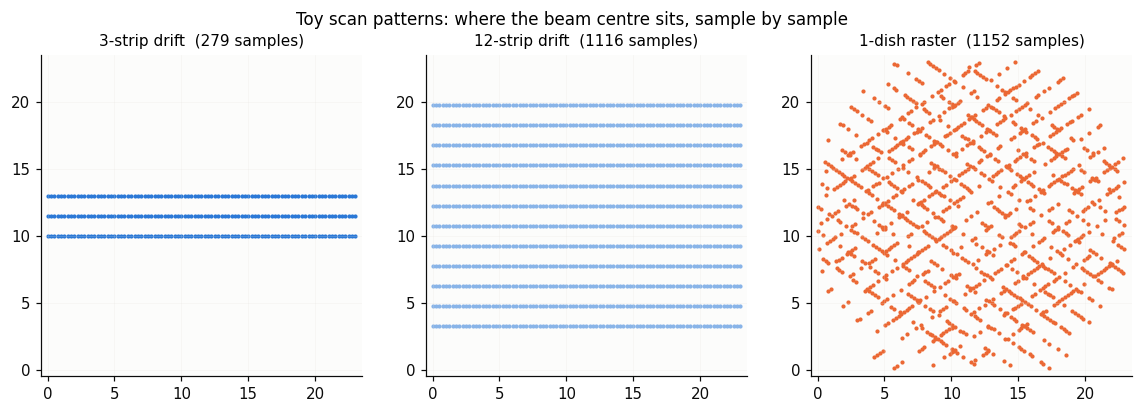

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.6), constrained_layout=True)
for a, k in zip(ax, STRATS):
    a.scatter(TOY[k]["pos"][:, 0], TOY[k]["pos"][:, 1], s=3, color=COL[k])
    a.set_title(f"{LAB[k]}  ({len(TOY[k]['pos'])} samples)", fontsize=10)
    a.set_xlim(-0.5, NG - 0.5); a.set_ylim(-0.5, NG - 0.5)
    a.set_aspect("equal"); a.grid(alpha=0.2)
fig.suptitle("Toy scan patterns: where the beam centre sits, sample by sample",
             fontsize=11)
plt.show()

## 1.1 Noiseless reconstruction is not the sky

Give the map-maker data with **no noise at all**. The map still differs from
the sky, and the difference has a closed form with no noise term in it:

$$m - s = -(I - WA)(s - \mu)$$

Everything on the right is the scan geometry (`WA`) acting on the sky. If the
scan measured every pattern, `WA = I` and the difference would be zero. It is
not, and the part that is left is what the paper calls the **beam + prior
floor**: the sky the strategy never measured, filled in from the prior.

In [6]:
rng = np.random.default_rng(SEED)
kx, ky = np.meshgrid(np.fft.fftfreq(NG), np.fft.fftfreq(NG), indexing="ij")
kgrid = np.hypot(kx, ky)
amp = np.zeros_like(kgrid); amp[kgrid > 0] = kgrid[kgrid > 0] ** -2.0
fg_map = np.real(np.fft.ifft2(np.fft.fft2(rng.normal(size=(NG, NG))) * amp))
fg_map = 20.0 + 3.0 * fg_map / fg_map.std()        # "foreground", ~20 K
hi_map = 3e-3 * rng.normal(size=(NG, NG))          # "H I", 1e-4 of it
s_toy = (fg_map + hi_map).ravel()
mu_toy = np.full(NPX, fg_map.mean())
sigma_p_toy = float(fg_map.std())

# the paper measures the residual away from the patch edge; so does the toy
INT = ((np.abs(PIX[:, 0] - (NG / 2 - 0.5)) <= 4)
       & (np.abs(PIX[:, 1] - (NG / 2 - 0.5)) <= 4))

for k, v in TOY.items():
    A = beam_rows(v["pos"], FWHM0)
    W, Minv = wiener(A, sigma_p_toy)
    v["WA"] = W @ A
    v["m"] = W @ (A @ s_toy) + Minv @ (mu_toy / sigma_p_toy ** 2)
    v["resid"] = v["m"] - s_toy
    predicted = -(np.eye(NPX) - v["WA"]) @ (s_toy - mu_toy)
    v["identity"] = float(np.abs(v["resid"] - predicted).max()
                          / np.abs(v["resid"]).max())
    print(f"{LAB[k]:16s} |m - s + (I - WA)(s - mu)| / |m - s| = "
          f"{v['identity']:.1e}   <- the identity holds to round-off")

3-strip drift    |m - s + (I - WA)(s - mu)| / |m - s| = 3.5e-14   <- the identity holds to round-off


12-strip drift   |m - s + (I - WA)(s - mu)| / |m - s| = 5.0e-14   <- the identity holds to round-off


1-dish raster    |m - s + (I - WA)(s - mu)| / |m - s| = 5.8e-14   <- the identity holds to round-off


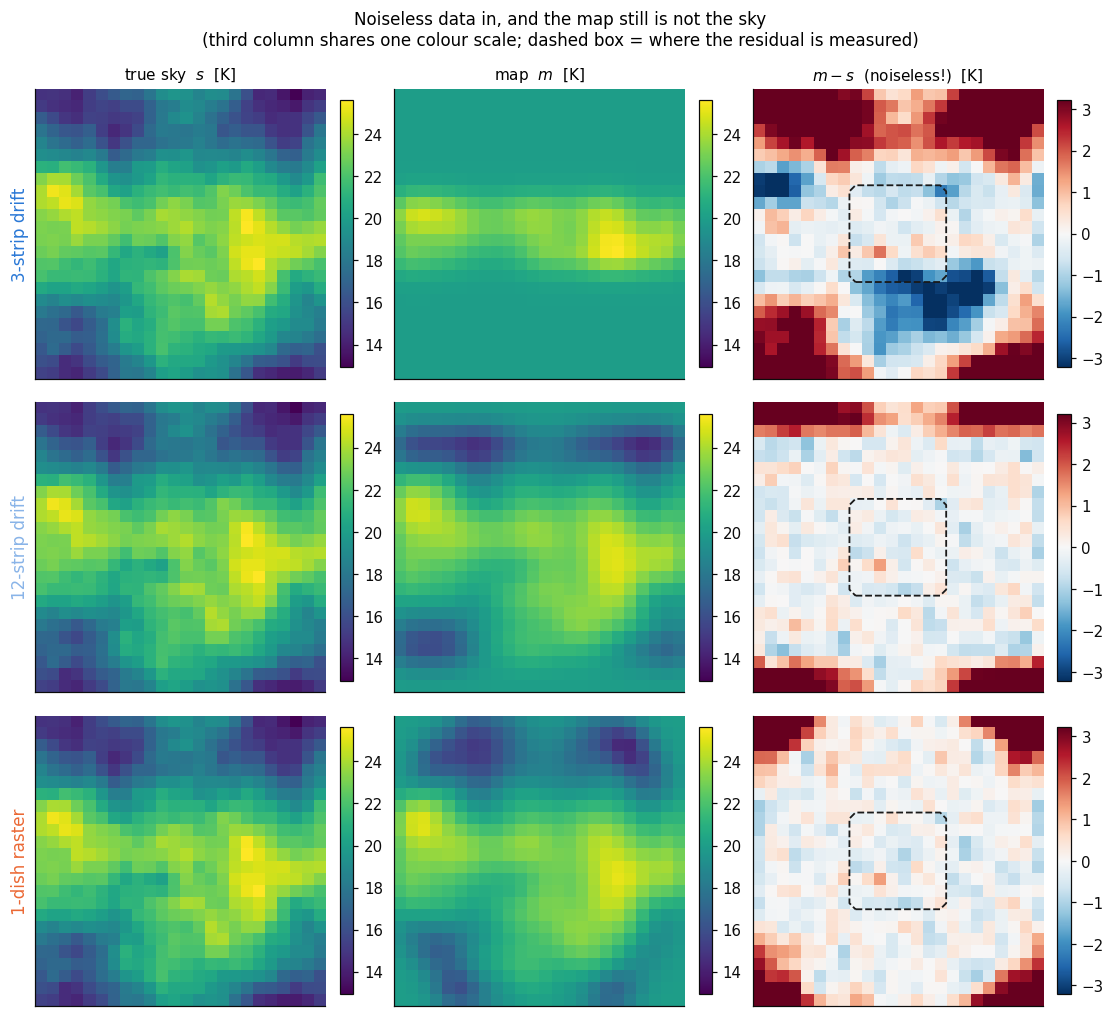

The residual is structured, not random: it is sky, not noise.


In [7]:
fig, ax = plt.subplots(3, 3, figsize=(10.0, 9.2), constrained_layout=True)
sky_lo, sky_hi = s_toy.min(), s_toy.max()
rlim = max(np.abs(TOY[k]["resid"][INT]).max() for k in STRATS)
for r, k in enumerate(STRATS):
    v = TOY[k]
    panels = [(s_toy.reshape(NG, NG), "true sky  $s$  [K]", "viridis",
               sky_lo, sky_hi),
              (v["m"].reshape(NG, NG), "map  $m$  [K]", "viridis",
               sky_lo, sky_hi),
              (v["resid"].reshape(NG, NG), "$m - s$  (noiseless!)  [K]",
               "RdBu_r", -rlim, rlim)]
    for c, (img, ttl, cm, lo, hi) in enumerate(panels):
        im = ax[r, c].imshow(img, origin="lower", cmap=cm, vmin=lo, vmax=hi)
        plt.colorbar(im, ax=ax[r, c], fraction=0.046)
        if r == 0:
            ax[r, c].set_title(ttl, fontsize=10)
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([]); ax[r, c].grid(False)
        if c == 2:      # outline the region the numbers are quoted on
            ax[r, c].contour(INT.reshape(NG, NG), levels=[0.5], colors="0.1",
                             linewidths=1.2, linestyles="--")
    ax[r, 0].set_ylabel(LAB[k], color=COL[k], fontsize=11)
fig.suptitle("Noiseless data in, and the map still is not the sky\n"
             "(third column shares one colour scale; dashed box = where the "
             "residual is measured)", fontsize=11)
plt.show()
print("The residual is structured, not random: it is sky, not noise.")

## 1.2 Which sky patterns go unmeasured

`WA` is symmetric here, so it has eigenvectors (sky patterns) with
eigenvalues between 0 and 1. An eigenvalue near **1** means that pattern is
measured by the data; near **0** means it is supplied by the prior, and the
survey learned nothing about it. The near-zero eigenvectors *are* the floor's
building blocks.

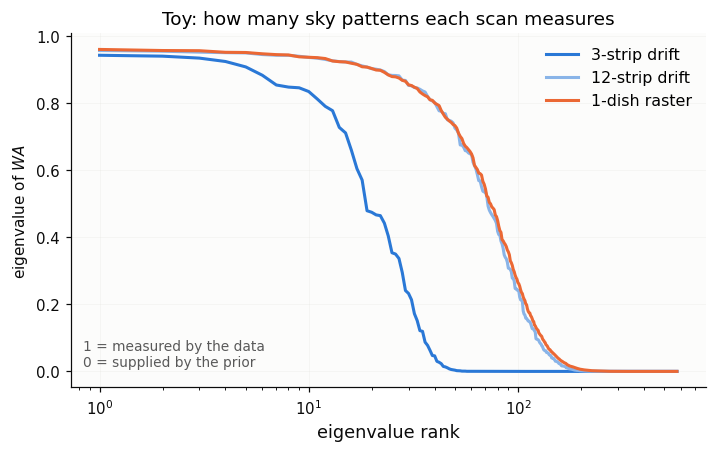

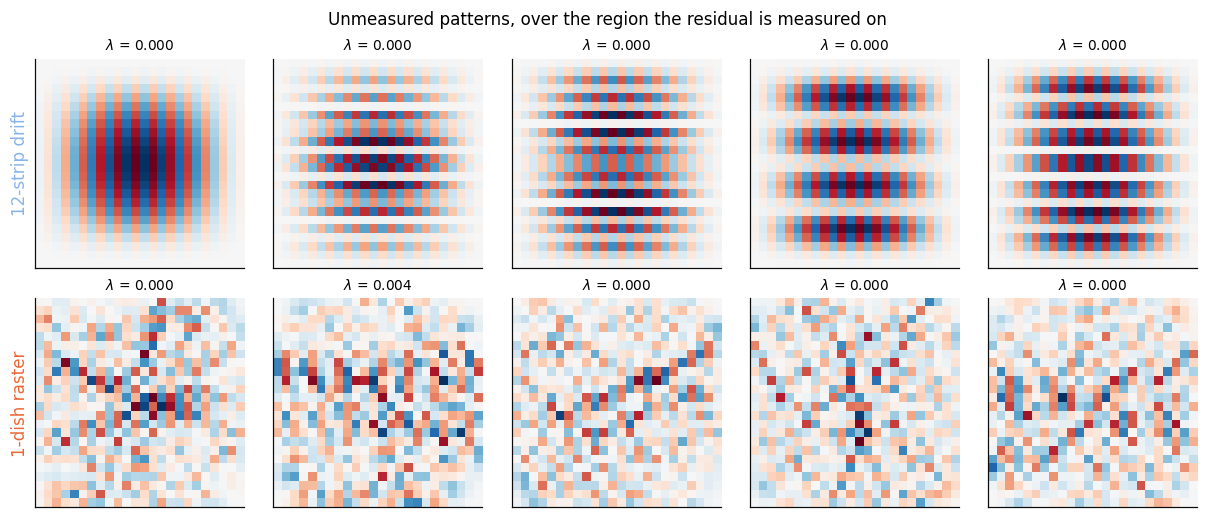

The drift's run along its scan direction. A pattern constant along the
track and varying across it is the hardest thing for a single scan
direction to see -- and every drift track has the same direction.


In [8]:
for k, v in TOY.items():
    w, V = np.linalg.eigh((v["WA"] + v["WA"].T) / 2)
    v["w"], v["V"] = w[::-1], V[:, ::-1]

fig, ax = plt.subplots(figsize=(6.4, 4.0), constrained_layout=True)
for k in STRATS:
    ax.plot(np.arange(1, NPX + 1), TOY[k]["w"], color=COL[k], label=LAB[k])
ax.set_xscale("log"); ax.set_xlabel("eigenvalue rank")
ax.set_ylabel("eigenvalue of $WA$", fontsize=10)
ax.annotate("1 = measured by the data\n0 = supplied by the prior", (0.02, 0.06),
            xycoords="axes fraction", fontsize=9, color="0.35")
ax.legend(); ax.set_title("Toy: how many sky patterns each scan measures")
plt.show()

# the least-measured patterns that still live inside the interior region
fig, ax = plt.subplots(2, 5, figsize=(11.0, 4.6), constrained_layout=True)
for r, k in enumerate(("drift12", "raster")):
    v = TOY[k]
    inside = np.argsort(-(v["V"] ** 2 * INT[:, None]).sum(axis=0)
                        * (v["w"] < 0.05))[:5]
    for c, i in enumerate(inside):
        img = v["V"][:, i].reshape(NG, NG)
        lim = np.abs(img).max()
        ax[r, c].imshow(img, origin="lower", cmap="RdBu_r",
                        vmin=-lim, vmax=lim)
        ax[r, c].set_title(f"$\\lambda$ = {v['w'][i]:.3f}", fontsize=9)
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([]); ax[r, c].grid(False)
    ax[r, 0].set_ylabel(LAB[k], color=COL[k], fontsize=11)
fig.suptitle("Unmeasured patterns, over the region the residual is measured on",
             fontsize=11)
plt.show()
print("The drift's run along its scan direction. A pattern constant along the")
print("track and varying across it is the hardest thing for a single scan")
print("direction to see -- and every drift track has the same direction.")

## 1.3 `tr(WA)` is a mode count &mdash; and not a sufficient one

Each eigenvalue contributes between 0 and 1 measured degrees of freedom, so
their sum

$$N_\mathrm{eff} = \mathrm{tr}(WA) = \sum_i \frac{\lambda_i}{\lambda_i + \sigma_p^{-2}}$$

counts the sky patterns the **data** constrain, with no threshold to choose.
It is the number the paper quotes. But it says *how many* patterns are
measured, not *which* &mdash; and it is which that sets the floor.

In [9]:
print("Toy, at matched sample cost where possible:")
for k, v in TOY.items():
    hi_i = hi_map.ravel()[INT].std()
    v["floor_int"] = float(v["resid"][INT].std() / hi_i)
    print(f"  {LAB[k]:16s} tr(WA) = {v['w'].sum():7.2f}   "
          f"interior residual / H I = {v['floor_int']:7.1f}")
print()
print(f"The 12-strip drift and the raster sit within "
      f"{abs(TOY['drift12']['w'].sum() / TOY['raster']['w'].sum() - 1) * 100:.0f}% "
      "of each other on tr(WA),")
print("yet they are not equally good. In the real data that gap is 10.5x")
print("(section 2.8); in this toy it is small and the sign is not even stable.")
print("Section 1.6 says why -- and it is the reason the paper measures the")
print("residual after a FREQUENCY clean rather than in a single map.")

Toy, at matched sample cost where possible:
  3-strip drift    tr(WA) =   20.38   interior residual / H I =   337.7
  12-strip drift   tr(WA) =   72.73   interior residual / H I =   153.3
  1-dish raster    tr(WA) =   75.64   interior residual / H I =   160.3

The 12-strip drift and the raster sit within 4% of each other on tr(WA),
yet they are not equally good. In the real data that gap is 10.5x
(section 2.8); in this toy it is small and the sign is not even stable.
Section 1.6 says why -- and it is the reason the paper measures the
residual after a FREQUENCY clean rather than in a single map.


## 1.4 Adding drift tracks

Each new strip adds measured patterns &mdash; but it also adds *sky*. The
tracks stay parallel, so the patterns that are hard to see stay hard to see.

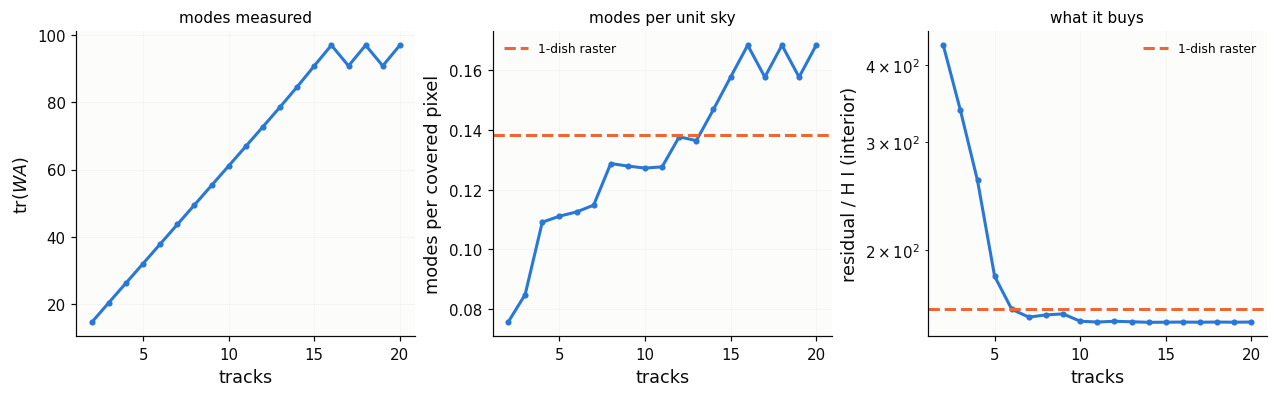

Middle panel: the mode COUNT keeps climbing, but modes per unit sky
flattens -- because each strip brings its own new sky with it.


In [10]:
Ns = np.arange(2, 21)
ladder_toy = []
for n in Ns:
    pos = budget(line_samples(0.0, int(n), 1.5, 0.25), int(96 * n))
    A = beam_rows(pos, FWHM0)
    W, Minv = wiener(A, sigma_p_toy)
    WA = W @ A
    m = W @ (A @ s_toy) + Minv @ (mu_toy / sigma_p_toy ** 2)
    cov = (np.abs(A).sum(axis=0) > 0.02 * np.abs(A).sum(axis=0).max())
    ladder_toy.append((n, float(np.trace(WA)), int(cov.sum()),
                       float((m - s_toy)[INT].std() / hi_map.ravel()[INT].std())))
ladder_toy = np.array(ladder_toy)

fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.5), constrained_layout=True)
ax[0].plot(ladder_toy[:, 0], ladder_toy[:, 1], "o-", color=COL["drift"], ms=3)
ax[0].set_xlabel("tracks"); ax[0].set_ylabel("tr($WA$)")
ax[0].set_title("modes measured", fontsize=10)
ax[1].plot(ladder_toy[:, 0], ladder_toy[:, 1] / ladder_toy[:, 2], "o-",
           color=COL["drift"], ms=3)
ax[1].axhline(TOY["raster"]["w"].sum()
              / (np.abs(beam_rows(TOY["raster"]["pos"], FWHM0)).sum(axis=0)
                 > 0.02 * np.abs(beam_rows(TOY["raster"]["pos"], FWHM0)).sum(axis=0).max()).sum(),
              color=COL["raster"], ls="--", label=LAB["raster"])
ax[1].set_xlabel("tracks"); ax[1].set_ylabel("modes per covered pixel")
ax[1].set_title("modes per unit sky", fontsize=10); ax[1].legend(fontsize=8)
ax[2].semilogy(ladder_toy[:, 0], ladder_toy[:, 3], "o-", color=COL["drift"], ms=3)
ax[2].axhline(TOY["raster"]["floor_int"], color=COL["raster"], ls="--",
              label=LAB["raster"])
ax[2].set_xlabel("tracks"); ax[2].set_ylabel("residual / H I (interior)")
ax[2].set_title("what it buys", fontsize=10); ax[2].legend(fontsize=8)
plt.show()
print("Middle panel: the mode COUNT keeps climbing, but modes per unit sky")
print("flattens -- because each strip brings its own new sky with it.")

## 1.5 The floor is not smooth in frequency

A real survey has many frequency channels, and the beam narrows across the
band (`FWHM = 1.22 lambda / D`). So `A` &mdash; and therefore `WA`, and
therefore the floor &mdash; is **different in every channel**.

That matters because foreground removal works by throwing away the few
frequency patterns that carry almost all the variance. This is **PCA
cleaning**: build the channel&times;channel covariance of the map, and
subtract its leading eigenmodes. A foreground that is one smooth spectrum
times a fixed spatial pattern is *rank one* &mdash; a single mode removes it
completely. A floor that changes shape with frequency is not.

In [11]:
NCH = 16
nu = np.linspace(350.0, 400.0, NCH)
fwhm_nu = FWHM0 * 350.0 / nu                      # 1.22 lambda / D
FG_c = fg_map.ravel()[None, :] * (nu[:, None] / 350.0) ** -2.7   # rank 1
HI_c = 3e-3 * np.random.default_rng(11).normal(size=(NCH, NPX))
S_c = FG_c + HI_c

def pca_clean_toy(cube, nmodes):
    x = cube - cube.mean(axis=1, keepdims=True)
    _, V = np.linalg.eigh(x @ x.T / x.shape[1])
    V = V[:, ::-1][:, :nmodes]
    return x - V @ (V.T @ x)

def freq_rank(cube, frac=0.999):
    x = cube - cube.mean(axis=1, keepdims=True)
    w = np.linalg.eigvalsh(x @ x.T / x.shape[1])[::-1]
    return int(np.searchsorted(np.cumsum(w / w.sum()), frac) + 1)

toy_clean = {}
for k, v in TOY.items():
    M_c, FL_c = [], []
    for i in range(NCH):
        A = beam_rows(v["pos"], fwhm_nu[i])
        sp = float(FG_c[i].std())
        W, Minv = wiener(A, sp)
        M_c.append(W @ (A @ S_c[i])
                   + Minv @ (np.full(NPX, FG_c[i].mean()) / sp ** 2))
        FL_c.append((W @ A) @ FG_c[i] - FG_c[i])
    M_c, FL_c = np.asarray(M_c), np.asarray(FL_c)
    hi_i = HI_c[:, INT].std()
    toy_clean[k] = dict(
        rank_fg=freq_rank(FG_c), rank_floor=freq_rank(FL_c),
        curve=[float(pca_clean_toy(M_c, n)[:, INT].std() / hi_i)
               for n in (1, 2, 3, 4)])

print(f"frequency modes to carry 99.9% of the variance "
      f"(the lower, the easier PCA's job):")
print(f"  toy foreground                       {toy_clean['drift']['rank_fg']}")
for k in STRATS:
    print(f"  toy floor, {LAB[k]:20s}      {toy_clean[k]['rank_floor']}")
print()
print("residual / H I after removing n PCA modes (interior):")
print("                      n=1      n=2      n=3      n=4")
for k in STRATS:
    print(f"  {LAB[k]:18s}" + "".join(f"{v:9.2f}" for v in toy_clean[k]["curve"]))

frequency modes to carry 99.9% of the variance (the lower, the easier PCA's job):
  toy foreground                       1
  toy floor, 3-strip drift             2
  toy floor, 12-strip drift            2
  toy floor, 1-dish raster             2

residual / H I after removing n PCA modes (interior):
                      n=1      n=2      n=3      n=4
  3-strip drift         13.87     0.42     0.21     0.19
  12-strip drift         2.78     0.38     0.27     0.25
  1-dish raster          4.07     0.43     0.27     0.25


## 1.6 What the toy does and does not reproduce

Being clear about this matters more than the toy looking impressive.

**It does reproduce**

1. noiseless data does not give the sky back (1.1), and the closed form has
   no noise term in it;
2. the unmeasured patterns of a single-direction scan run along that
   direction (1.2);
3. `tr(WA)` counts modes but does not rank strategies on its own (1.3);
4. adding parallel tracks adds sky as fast as it adds modes (1.4);
5. the floor changes with frequency because the beam does, so it is harder
   for PCA to remove than the foreground is (1.5).

**It does not reproduce** the size of the cross-linking advantage. In the real
data the raster's floor is 10.5&times; below a mode-matched drift ladder; in
the toy the two are within tens of per cent and the sign is not stable. Two
honest reasons:

* the toy's floor is nearly **rank 1 in frequency**, so 2&ndash;4 PCA modes
  clear it below the H&nbsp;I. The real floor needs 2&ndash;6 modes and never
  clears &mdash; measured in section 2.6. Real chromaticity comes from more
  than beam width: the pixel set, the prior width `sigma_p(nu)` and the sky's
  own spectral behaviour all move across the band;
* the real residual is quoted as a **power spectrum along the line of sight
  after cleaning**, not as a map rms, and that is the statistic the drift does
  badly on.

So: use the toy for the mechanisms, and section 2 for the numbers.

---
# 2. The real pipeline, one step at a time

350&ndash;400&nbsp;MHz, `N_side` 64, 32 channels, 3&nbsp;h of observing.
Everything below is loaded from stored results.

In [12]:
import healpy as hp
import ska_hi_analysis as A
import ska_hi_experiment as X
get_ipython().run_line_magic("matplotlib", "inline")

ABL  = np.load(os.path.join(RES, "hi_ablation_amp350_f350_400_nc32_ns64.npz"),
               allow_pickle=True)                 # run tag: amp350
EXP  = np.load(os.path.join(RES, "hi_experiment_matched_f350_400_nc32_ns64.npz"),
               allow_pickle=True)                 # run tag: matched
TFX  = np.load(os.path.join(RES, "hi_experiment_pin350_f350_400_nc32_ns64.npz"),
               allow_pickle=True)                 # run tag: pin350
KMOD = np.load(os.path.join(RES, "hi_kmodes_f350_ns64.npz"), allow_pickle=True)
LADD = np.load(os.path.join(RES, "hi_ladder_long_ns64.npz"))
MCHK = np.load(os.path.join(RES, "hi_modecheck_f350_400_ns64.npz"))

FREQS   = EXP["freqs"]
COMMON  = np.asarray(EXP["common"])
INTMASK = EXP["interior"]
INTPIX  = COMMON[INTMASK]
NSIDE   = int(X.NSIDE)
DR      = float(EXP["dr_mpc"])
PIXAREA = hp.nside2pixarea(NSIDE, degrees=True)

print(f"channels        {len(FREQS)}  ({FREQS[0]:.2f} - {FREQS[-1]:.2f} MHz)")
print(f"common patch    {len(COMMON)} px   interior {len(INTPIX)} px "
      f"= {len(INTPIX) * PIXAREA:.1f} deg^2")
_ra, _dec = hp.pix2ang(NSIDE, COMMON, lonlat=True)
LONRA = [float(np.floor(_ra.min()) - 1), float(np.ceil(_ra.max()) + 1)]
LATRA = [float(np.floor(_dec.min()) - 1), float(np.ceil(_dec.max()) + 1)]
print(f"channel depth   {DR:.2f} Mpc")
print(f"patch spans     RA {LONRA[0]:.0f}-{LONRA[1]:.0f}, "
      f"Dec {LATRA[0]:.0f}-{LATRA[1]:.0f} deg")

channels        32  (350.78 - 399.22 MHz)
common patch    277 px   interior 119 px = 99.9 deg^2
channel depth   16.39 Mpc
patch spans     RA 146-171, Dec 3-16 deg


## 2.1 The scan tracks, and the hits each leaves

The drift parks the dish: the sky rotates through a fixed beam, so the
boresight traces a line of constant declination, always swept west to east.
Its **position angle is 90 degrees at every azimuth** &mdash; pointing the
dish elsewhere changes *which* declination, not the direction. That is why a
parked dish cannot cross-link. The raster slews in azimuth, so its rising and
setting passes cross on the sky.

In [13]:
import ska_raster_sampling as RS
get_ipython().run_line_magic("matplotlib", "inline")

pa_rows = []
for k in ("drift", "raster"):
    for i, (ra, dec, az) in enumerate(RS.tracks(k)):
        dra = np.diff(np.unwrap(np.radians(ra))) * np.cos(np.radians(dec[:-1]))
        pa = np.degrees(np.arctan2(dra, np.diff(np.radians(dec)))) % 180.0
        pa_rows.append((LAB[k], f"pass {i}", float(np.median(pa)),
                        float(np.std(pa))))
display(Markdown("| strategy | pass | track position angle | scatter |\n"
                 "|---|---|---:|---:|\n"
                 + "\n".join(f"| {a} | {b} | {c:.2f} deg | {d:.3f} deg |"
                             for a, b, c, d in pa_rows)))

| strategy | pass | track position angle | scatter |
|---|---|---:|---:|
| 3-strip drift | pass 0 | 89.95 deg | 0.009 deg |
| 3-strip drift | pass 1 | 89.95 deg | 0.009 deg |
| 3-strip drift | pass 2 | 89.95 deg | 0.010 deg |
| 1-dish raster | pass 0 | 127.95 deg | 3.634 deg |
| 1-dish raster | pass 1 | 51.95 deg | 3.635 deg |

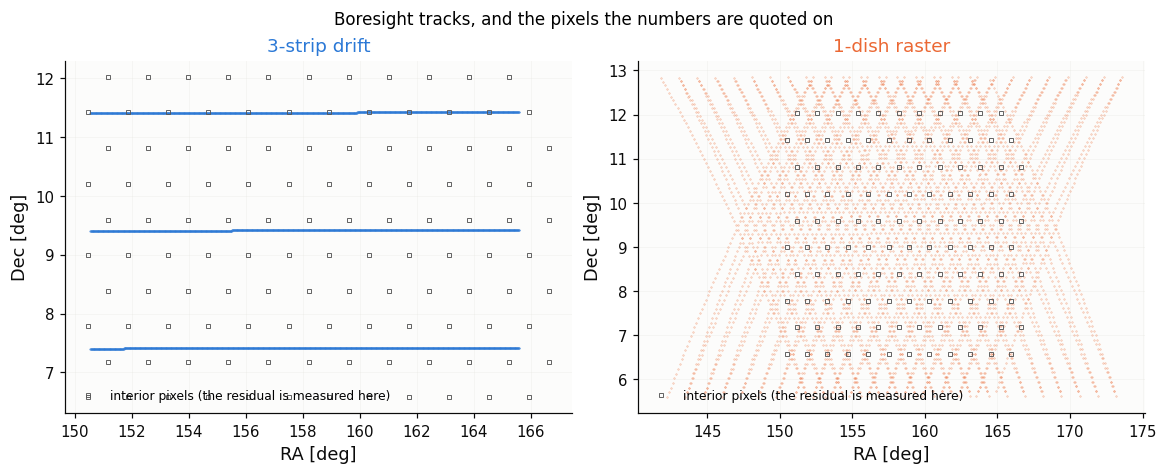

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)
for a, k in zip(ax, ("drift", "raster")):
    for ra, dec, _ in RS.tracks(k):
        a.plot(ra, dec, ".", ms=0.7, color=COL[k], alpha=0.5)
    ipix_ra, ipix_dec = hp.pix2ang(NSIDE, INTPIX, lonlat=True)
    a.plot(ipix_ra, ipix_dec, "s", ms=3, mfc="none", mec="0.35", mew=0.6,
           label="interior pixels (the residual is measured here)")
    a.set_xlabel("RA [deg]"); a.set_ylabel("Dec [deg]")
    a.set_title(LAB[k], color=COL[k]); a.legend(fontsize=8, loc="lower left", framealpha=0.9)
fig.suptitle("Boresight tracks, and the pixels the numbers are quoted on",
             fontsize=11)
plt.show()

## 2.2 The input sky: why a tiny leak of foreground matters

The Galaxy is thousands of times brighter than the H&nbsp;I. That ratio is the
whole problem: a scan can measure 99 per cent of the foreground perfectly and
*still* leave a residual far above the signal.

At 375.78 MHz, over the common patch:
  foreground mean                                             16.96
  foreground rms about its mean                               1.786
  H I rms                                                      0.24
  foreground mean / H I rms                               7.067e+04
  foreground rms / H I rms                                     7442


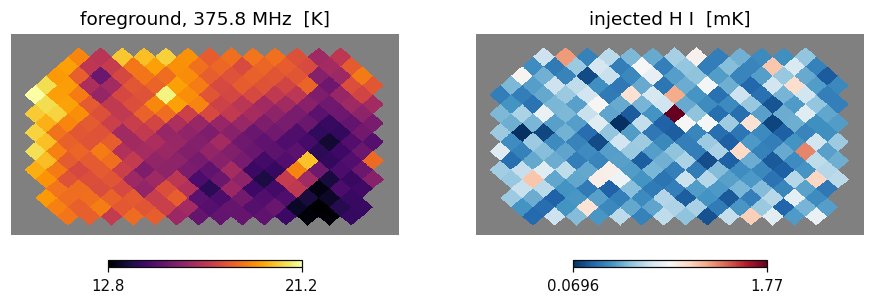


The foreground's total brightness is 70,675x the H I rms, and
its spatial STRUCTURE -- what a clean actually has to remove -- is
7,442x. Leave 0.1% of that behind and you still have
several times the signal left over.


In [15]:
from ska_common import gdsm_equatorial_sky_model

ch = len(FREQS) // 2
fg_ch = gdsm_equatorial_sky_model(freq=float(FREQS[ch]), nside=NSIDE)[COMMON]
hi_ch = np.asarray(EXP["drift_hi_true"])[ch]

print("At %.2f MHz, over the common patch:" % FREQS[ch])
record("foreground mean", float(fg_ch.mean()), unit="K",
       npz="(built live)", code_ref="ska_common.gdsm_equatorial_sky_model")
record("foreground rms about its mean", float(fg_ch.std()), unit="K",
       npz="(built live)", code_ref="ska_common.gdsm_equatorial_sky_model")
record("H I rms", float(hi_ch.std() * 1e3), unit="mK",
       npz="hi_experiment_matched : drift_hi_true",
       code_ref="ska_hi_mock.build_hi_cube", run="matched")
ratio = record("foreground mean / H I rms", float(fg_ch.mean() / hi_ch.std()),
               unit="dimensionless", npz="(derived)",
               code_ref="this notebook",
               note="the total brightness the clean has to subtract")
ratio_rms = record("foreground rms / H I rms",
                   float(fg_ch.std() / hi_ch.std()),
                   unit="dimensionless", npz="(derived)",
                   code_ref="this notebook",
                   note="the STRUCTURE the clean has to subtract; this is the "
                        "number that matters, since a constant offset is "
                        "removed by the mean subtraction")

fig, ax = plt.subplots(1, 2, figsize=(10.0, 3.6))
for a, (val, ttl, cm) in zip(ax, [
        (fg_ch, f"foreground, {FREQS[ch]:.1f} MHz  [K]", "inferno"),
        (hi_ch * 1e3, "injected H I  [mK]", "RdBu_r")]):
    m = np.full(hp.nside2npix(NSIDE), np.nan); m[COMMON] = val
    plt.axes(a)
    hp.cartview(m, lonra=LONRA, latra=LATRA, title=ttl, cmap=cm, hold=True,
                notext=True, cbar=True)
plt.show()
print(f"\nThe foreground's total brightness is {ratio:,.0f}x the H I rms, and")
print(f"its spatial STRUCTURE -- what a clean actually has to remove -- is")
print(f"{ratio_rms:,.0f}x. Leave 0.1% of that behind and you still have")
print("several times the signal left over.")

## 2.3 The H I *as the survey sees it*

Before any foreground cleaning, the H&nbsp;I in the map is not the H&nbsp;I in
the sky: it has been through the beam, the scan and the prior. The pipeline
stores this as `x_HI = W A s_HI` (key `{strategy}_hi_mapmade`), computed by
`ska_hi_analysis.response`, which solves the map-maker on the H&nbsp;I's own
TOD with a zero prior mean.

In [16]:
print("H I rms, true vs map-made, over the interior (common resolution):")
for k in ("drift", "raster"):
    true_i = np.asarray(EXP[f"{k}_hi_true"])[:, INTMASK]
    mm_i = A.common_resolution(np.asarray(EXP[f"{k}_hi_mapmade"]),
                               FREQS, COMMON, NSIDE)[:, INTMASK]
    print(f"  {LAB[k]:16s} true {true_i.std()*1e3:6.4f} mK   "
          f"map-made {mm_i.std()*1e3:6.4f} mK   "
          f"kept {mm_i.std()/true_i.std():.3f}")
print("\nSo some H I is lost before the foreground clean even starts.")

H I rms, true vs map-made, over the interior (common resolution):


/home/geoff/limTOD/examples/SKA/ska_hi_analysis.py:125: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  out[i] = hp.smoothing(full, fwhm=np.radians(kernel), verbose=False)[pix]


  3-strip drift    true 0.2302 mK   map-made 0.1150 mK   kept 0.500


  1-dish raster    true 0.2302 mK   map-made 0.0940 mK   kept 0.408

So some H I is lost before the foreground clean even starts.


## 2.4 How many sky modes each strategy measures

`tr(WA)` again, now on the real operators. The drift's is computed live from
the cached operator; it is the prior *reference* strategy, so its
amplitude-only rescaling factor is exactly 1 and the live number is the
published one. The other two are read from the stored mode-count file.

   [prior] f350: c = 1.000000 (reference, or set_strategy not called)


tr(WA), the number of sky modes the DATA constrain:
  tr(WA), 3-strip drift (live from the operator)              38.78   paper 38.78      matches paper
  tr(WA), 12-strip drift (stored)                             145.4   paper 145.3      matches paper
  tr(WA), 1-dish raster (stored)                              118.5   paper 118.5      matches paper


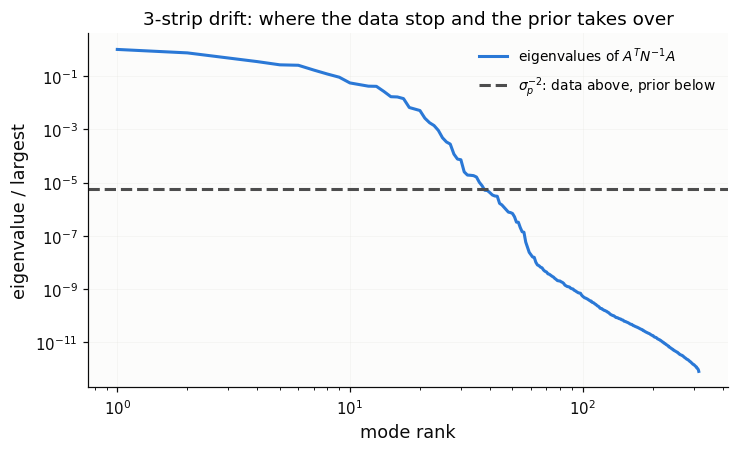

37 of 316 patch pixels sit on the data
side of that line; tr(WA) counts them with a smooth weight instead of
a hard threshold.


In [17]:
import pickle
import ska_hi_prior as prior
import ska_hi_kmodes as K
get_ipython().run_line_magic("matplotlib", "inline")   # K also forces Agg

prior.PINNED = True
band = K.BANDS["f350"]
with open(K.operator_path(band, "drift"), "rb") as f:
    mm_drift = pickle.load(f)
lam, U, s_inv, pix = K.eig_decomposition(mm_drift, band)
w_drift = lam / (lam + s_inv)

print("tr(WA), the number of sky modes the DATA constrain:")
record("tr(WA), 3-strip drift (live from the operator)", float(w_drift.sum()),
       unit="modes", npz="hi_cache/op_drift_f350.781_ns64.pkl",
       code_ref="ska_hi_kmodes.eig_decomposition", paper=38.78, tol=0.01)
for k, want in (("drift12", 145.35), ("raster", 118.52)):
    record(f"tr(WA), {LAB[k]} (stored)", float(KMOD[f"{k}_total"]),
           unit="modes", npz="hi_kmodes_f350_ns64.npz : %s_total" % k,
           code_ref="ska_hi_kmodes.compute", paper=want, tol=0.01)

fig, ax = plt.subplots(figsize=(6.6, 4.0), constrained_layout=True)
ax.semilogy(np.arange(1, len(lam) + 1), np.maximum(lam, 1e-30) / lam.max(),
            color=COL["drift"], label="eigenvalues of $A^T N^{-1} A$")
ax.axhline(s_inv / lam.max(), color="0.3", ls="--",
           label="$\\sigma_p^{-2}$: data above, prior below")
ax.set_xscale("log"); ax.set_xlabel("mode rank")
ax.set_ylabel("eigenvalue / largest"); ax.legend(fontsize=9)
ax.set_title(f"{LAB['drift']}: where the data stop and the prior takes over")
plt.show()
print(f"{int((lam > s_inv).sum())} of {len(lam)} patch pixels sit on the data")
print("side of that line; tr(WA) counts them with a smooth weight instead of")
print("a hard threshold.")

## 2.5 The floor, and exactly how the code computes it

**A correction to how this is often described.** The paper defines the floor
as `r_floor = (I - WA) s` (its Eq. for the floor). The quantity actually
*measured* and stored is not that subtraction. In
`ska_hi_ablation.py` the `floor` arm is

```python
cubes["floor"].append(A.solve(mm, [c + h for c, h in zip(clean, hitod)],
                              truth, mu, freq_mhz=f)[sel])
```

&mdash; the map-maker run on **noiseless** data (foreground TOD with the gain
and white noise divided back out, plus the injected H&nbsp;I), which is then
PCA-cleaned and turned into a line-of-sight power spectrum. So
`{strategy}_cr_floor_{n}` is *the power of the cleaned noiseless map*, whose
content is leftover foreground plus the surviving H&nbsp;I &mdash; not
literally `(I - WA)s`. The two describe the same physics and the ratio quoted
in the paper is unaffected, but anyone reading the npz should know which is
which. This was checked against the code for this notebook.

In [18]:
# the ratio the paper quotes: amplitude of the cleaned noiseless map over the
# map-made H I, median over k_par bins, at 4 modes
NM = 4
floor_amp = {}
for k in STRATS:
    floor_amp[k] = float(np.median(np.sqrt(ABL[f"{k}_cr_floor_{NM}"]
                                           / ABL[f"{k}_cr_p_hi"])))

print(f"floor / H I in amplitude, {NM} modes removed, common resolution, "
      "interior pixels:")
for k, want in (("drift", 399.6), ("drift12", 233.7), ("raster", 22.3)):
    record(f"floor/H I, {LAB[k]}", floor_amp[k], unit="amplitude ratio",
           npz=f"hi_ablation_amp350 : {k}_cr_floor_4 / {k}_cr_p_hi",
           code_ref="ska_hi_ablation.main", run="amp350", paper=want, tol=0.06)
record("matched-density ratio, 12-strip drift / raster",
       floor_amp["drift12"] / floor_amp["raster"], unit="ratio",
       npz="(derived)", code_ref="this notebook", paper=10.5, tol=0.05)

floor / H I in amplitude, 4 modes removed, common resolution, interior pixels:
  floor/H I, 3-strip drift                                    399.6   paper 399.6      matches paper
  floor/H I, 12-strip drift                                   233.7   paper 233.7      matches paper
  floor/H I, 1-dish raster                                     22.3   paper 22.3       matches paper
  matched-density ratio, 12-strip drift / raster              10.48   paper 10.5       matches paper


10.480385023695234

/home/geoff/limTOD/examples/SKA/ska_hi_analysis.py:125: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  out[i] = hp.smoothing(full, fwhm=np.radians(kernel), verbose=False)[pix]


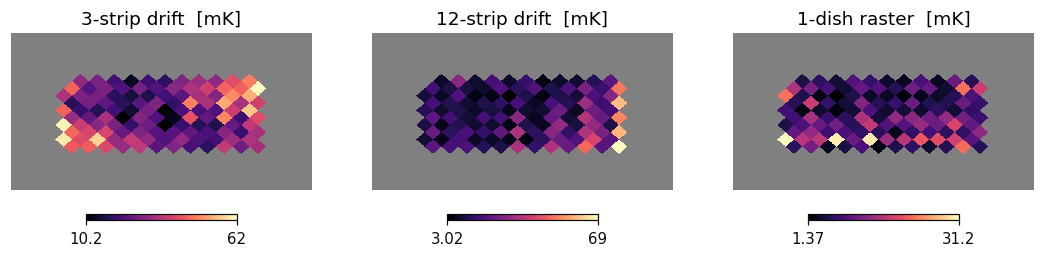

Post-clean residual per pixel, 4 modes. Note the colour scales differ
by more than an order of magnitude between the drift and the raster.


In [19]:
# the same residual as a MAP: rebuild it by cleaning the stored data cube.
# (the ablation stores power spectra only, so the map is rebuilt here; this
#  cube carries the simulated noise, which sits 1-9% above the noiseless arm
#  in power -- stated rather than hidden.)
fig, ax = plt.subplots(1, 3, figsize=(12.0, 3.6))
for a, k in zip(ax, STRATS):
    if f"{k}_data_cube" not in EXP:
        a.axis("off"); a.set_title(f"{LAB[k]}: no cube stored", fontsize=10)
        continue
    cr = A.common_resolution(np.asarray(EXP[f"{k}_data_cube"]),
                             FREQS, COMMON, NSIDE)[:, INTMASK]
    cl = A.pca_clean(cr, NM)
    rms = cl.std(axis=0)
    m = np.full(hp.nside2npix(NSIDE), np.nan); m[INTPIX] = rms * 1e3
    plt.axes(a)
    hp.cartview(m, lonra=LONRA, latra=LATRA, title=f"{LAB[k]}  [mK]",
                cmap="magma", hold=True, notext=True, cbar=True)
plt.show()
print("Post-clean residual per pixel, 4 modes. Note the colour scales differ")
print("by more than an order of magnitude between the drift and the raster.")

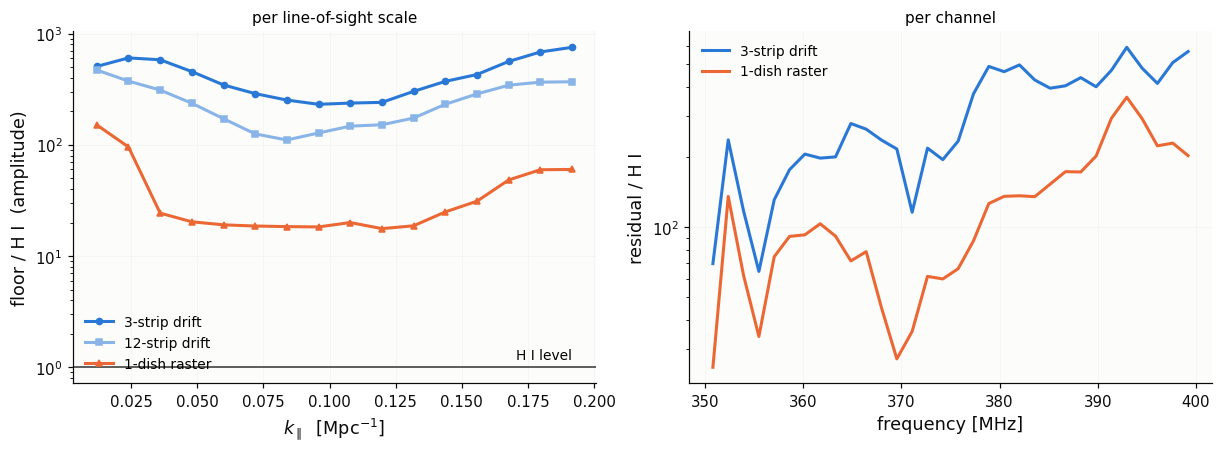

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0), constrained_layout=True)
kk = ABL["drift_cr_k"]
for k in STRATS:
    ax[0].semilogy(kk, np.sqrt(ABL[f"{k}_cr_floor_{NM}"] / ABL[f"{k}_cr_p_hi"]),
                   color=COL[k], marker=P.PAPER_STRAT[k]["marker"], ms=4,
                   label=LAB[k])
ax[0].axhline(1.0, color="0.2", lw=1)
ax[0].annotate("H I level", (kk[-1], 1.0), xytext=(0, 5),
               textcoords="offset points", ha="right", fontsize=9)
ax[0].set_xlabel(r"$k_\parallel$  [Mpc$^{-1}$]")
ax[0].set_ylabel("floor / H I  (amplitude)")
ax[0].set_title("per line-of-sight scale", fontsize=10); ax[0].legend(fontsize=9)
for k in ("drift", "raster"):
    cr = A.common_resolution(np.asarray(EXP[f"{k}_data_cube"]),
                             FREQS, COMMON, NSIDE)[:, INTMASK]
    hi = A.common_resolution(np.asarray(EXP[f"{k}_hi_mapmade"]),
                             FREQS, COMMON, NSIDE)[:, INTMASK]
    cl = A.pca_clean(cr, NM)
    ax[1].semilogy(FREQS, cl.std(axis=1) / hi.std(axis=1), color=COL[k],
                   label=LAB[k])
ax[1].set_xlabel("frequency [MHz]"); ax[1].set_ylabel("residual / H I")
ax[1].set_title("per channel", fontsize=10); ax[1].legend(fontsize=9)
plt.show()

## 2.6 Why cleaning harder does not fix it

PCA removes the frequency patterns that carry the most variance. The
foreground is **one** such pattern. The floor is several &mdash; and some of
them look like the H&nbsp;I, so removing them removes signal too.

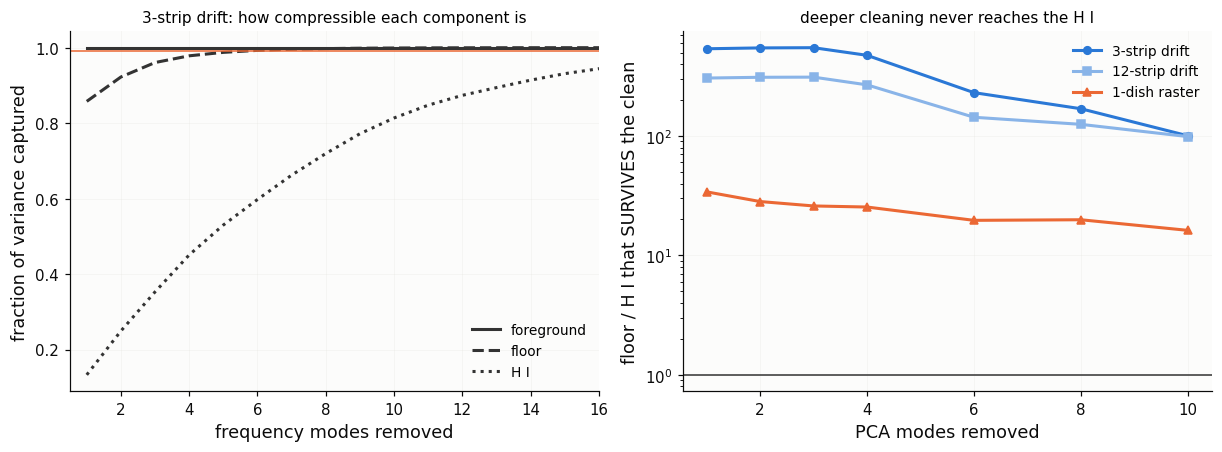

  modes for 99% of the variance, foreground    1
  modes for 99% of the variance, floor         6
  modes for 99% of the variance, H I          23


In [21]:
RANK = np.load(os.path.join(RES, "hi_rank_f350_400_nc32_ns64.npz"))
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0), constrained_layout=True)
for comp, sty, name in (("fg", "-", "foreground"), ("floor", "--", "floor"),
                        ("hi", ":", "H I")):
    w = RANK[f"drift_w_{comp}"]; w = np.cumsum(w / w.sum())
    ax[0].plot(np.arange(1, len(w) + 1), w, sty, color="0.2", label=name)
ax[0].axhline(0.99, color=COL["raster"], lw=1, ls="-")
ax[0].annotate("99%", (len(w), 0.99), xytext=(-4, 4),
               textcoords="offset points", ha="right", color=COL["raster"])
ax[0].set_xlim(0.5, 16); ax[0].set_xlabel("frequency modes removed")
ax[0].set_ylabel("fraction of variance captured")
ax[0].set_title(f"{LAB['drift']}: how compressible each component is",
                fontsize=10)
ax[0].legend(fontsize=9)

for k in STRATS:
    nm_grid = [int(v) for v in ABL["nmodes_grid"]]
    net = [float(np.median(np.sqrt(ABL[f"{k}_cr_floor_{n}"]
                                   / ABL[f"{k}_cr_p_hi"])))
           / float(np.median(TFX[f"{k}_cr_tf_{n}"])) for n in nm_grid]
    ax[1].semilogy(nm_grid, net, color=COL[k], marker=P.PAPER_STRAT[k]["marker"],
                   ms=5, label=LAB[k])
ax[1].axhline(1.0, color="0.2", lw=1)
ax[1].set_xlabel("PCA modes removed")
ax[1].set_ylabel("floor / H I that SURVIVES the clean")
ax[1].set_title("deeper cleaning never reaches the H I", fontsize=10)
ax[1].legend(fontsize=9)
plt.show()

for comp, name in (("fg", "foreground"), ("floor", "floor"), ("hi", "H I")):
    w = RANK[f"drift_w_{comp}"]; c = np.cumsum(w / w.sum())
    print(f"  modes for 99% of the variance, {name:11s} "
          f"{int(np.searchsorted(c, 0.99) + 1):3d}")

In [22]:
# the global minimum net residual, over every band, strategy and depth
best = (np.inf, None)
for tag, ab, ex, ss in [
        ("350-400", "hi_ablation_amp350_f350_400_nc32_ns64.npz",
         "hi_experiment_pin350_f350_400_nc32_ns64.npz", STRATS),
        ("675-725", "hi_ablation_amp700_f675_725_nc32_ns128.npz",
         "hi_experiment_matched700b_f675_725_nc32_ns128.npz",
         ("drift", "drift12m", "raster"))]:
    a_, e_ = (np.load(os.path.join(RES, ab)), np.load(os.path.join(RES, ex)))
    for s_ in ss:
        for n in [int(v) for v in a_["nmodes_grid"]]:
            v = (float(np.median(np.sqrt(a_[f"{s_}_cr_floor_{n}"]
                                         / a_[f"{s_}_cr_p_hi"])))
                 / float(np.median(e_[f"{s_}_cr_tf_{n}"])))
            if v < best[0]:
                best = (v, (tag, s_, n))
print(f"best case anywhere: {best[1][0]} MHz, {LAB.get(best[1][1], best[1][1])},"
      f" {best[1][2]} modes removed")
record("lowest net residual in any band, strategy or depth", best[0],
       unit="x the surviving H I",
       npz="hi_ablation_amp350/amp700 + hi_experiment_pin350/matched700b",
       code_ref="ska_hi_design.fig_cleaning_depth (ratio of medians)",
       paper=6.1, tol=0.1,
       note="the code divides median(sqrt(floor/HI)) by median(T); taking the "
            "median of the per-bin ratio instead gives 5.22, so the ordering "
            "of the two medians matters at the 15% level")
print("\nNothing, anywhere, in any band, at any cleaning depth, gets within a")
print("factor of six of the H I.")

best case anywhere: 675-725 MHz, 3-strip drift, 10 modes removed
  lowest net residual in any band, strategy or depth          6.133   paper 6.1        matches paper

Nothing, anywhere, in any band, at any cleaning depth, gets within a
factor of six of the H I.


## 2.7 The transfer function: cleaning destroys signal too

PCA cannot tell foreground from H&nbsp;I, so it removes some of both. How much
is measured by **injection**: add an independent mock H&nbsp;I cube to the
data, clean, and see how much of the mock comes back. That ratio is the
transfer function `T`.

It is a cross-power with the mock divided by the mock's *auto*-power, so `T`
is an **amplitude** ratio: the surviving H&nbsp;I power is `T^2`.

median T over k_par bins, 4 modes removed:
  T, 3-strip drift                                           0.8434   paper 0.843      matches paper
  T, 12-strip drift                                          0.8718   paper 0.872      matches paper
  T, 1-dish raster                                           0.8771   paper 0.877      matches paper


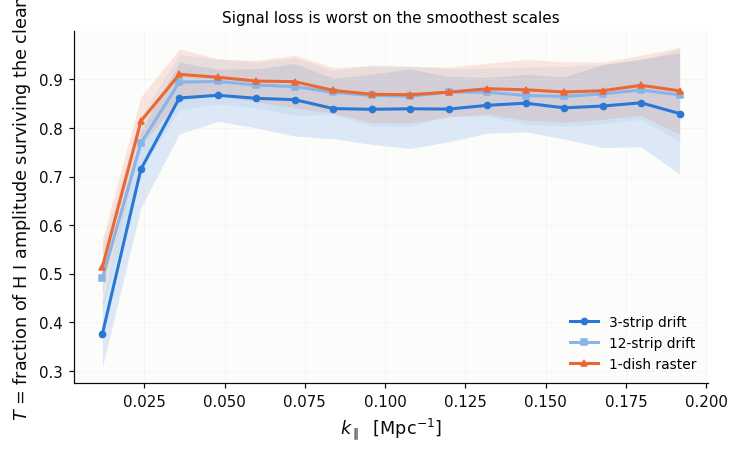

Loss is concentrated at low k_par -- the smoothest modes along the line
of sight, which are the ones that look most like a foreground.


In [23]:
print(f"median T over k_par bins, {NM} modes removed:")
for k, want in (("drift", 0.843), ("drift12", 0.872), ("raster", 0.877)):
    record(f"T, {LAB[k]}", float(np.median(TFX[f"{k}_cr_tf_{NM}"])),
           unit="amplitude ratio",
           npz=f"hi_experiment_pin350 : {k}_cr_tf_4",
           code_ref="ska_hi_analysis.transfer_function", run="pin350",
           paper=want, tol=0.002)

fig, ax = plt.subplots(figsize=(6.6, 4.0), constrained_layout=True)
for k in STRATS:
    ax.plot(ABL["drift_cr_k"], TFX[f"{k}_cr_tf_{NM}"], color=COL[k],
            marker=P.PAPER_STRAT[k]["marker"], ms=4, label=LAB[k])
    ax.fill_between(ABL["drift_cr_k"],
                    TFX[f"{k}_cr_tf_{NM}"] - TFX[f"{k}_cr_tf_scatter_{NM}"],
                    TFX[f"{k}_cr_tf_{NM}"] + TFX[f"{k}_cr_tf_scatter_{NM}"],
                    color=COL[k], alpha=0.15, lw=0)
ax.set_xlabel(r"$k_\parallel$  [Mpc$^{-1}$]")
ax.set_ylabel("$T$ = fraction of H I amplitude surviving the clean")
ax.set_title("Signal loss is worst on the smoothest scales", fontsize=10)
ax.legend(fontsize=9)
plt.show()
print("Loss is concentrated at low k_par -- the smoothest modes along the line")
print("of sight, which are the ones that look most like a foreground.")

## 2.8 The headline

In [24]:
display(Markdown(
    "| strategy | tr($WA$) | patch [deg$^2$] | modes / 100 deg$^2$ | "
    "floor / H I |\n|---|---:|---:|---:|---:|\n"
    + "\n".join(
        f"| {LAB[k]} | {float(KMOD[f'{k}_total']):.2f} | "
        f"{float(KMOD[f'{k}_area']):.1f} | "
        f"{100 * float(KMOD[f'{k}_total']) / float(KMOD[f'{k}_area']):.2f} | "
        f"**{floor_amp[k]:.1f}** |" for k in STRATS)))
print()
print("The 12-strip drift measures MORE modes per unit sky than the raster")
print(f"({100*float(KMOD['drift12_total'])/float(KMOD['drift12_area']):.2f} "
      f"against {100*float(KMOD['raster_total'])/float(KMOD['raster_area']):.2f})"
      " and still has a floor "
      f"{floor_amp['drift12']/floor_amp['raster']:.1f}x higher.")
print("Mode count is necessary. It is not sufficient.")

| strategy | tr($WA$) | patch [deg$^2$] | modes / 100 deg$^2$ | floor / H I |
|---|---:|---:|---:|---:|
| 3-strip drift | 38.78 | 265.2 | 14.62 | **399.6** |
| 12-strip drift | 145.35 | 674.8 | 21.54 | **233.7** |
| 1-dish raster | 118.52 | 574.1 | 20.64 | **22.3** |


The 12-strip drift measures MORE modes per unit sky than the raster
(21.54 against 20.64) and still has a floor 10.5x higher.
Mode count is necessary. It is not sufficient.


---
# 3. The two questions, answered

## 3.1 "Shouldn't noiseless data give back the H I exactly?"

No, and the reason is a chain of four steps, each measured above:

1. **The scan leaves sky patterns unmeasured** (1.1, 1.2). `WA` is not the
   identity: a parked dish sweeps every track in the same direction, so
   patterns that vary across that direction are poorly constrained. This has
   nothing to do with noise.
2. **The map-maker fills them from the prior** (1.1). The prior is a flat
   constant, so those patterns come back as *something wrong*, and the error
   is `-(I - WA)(s - mu)`.
3. **The foreground in those patterns is enormous** (2.2). It is thousands of
   times the H&nbsp;I, so the fraction that leaks through still outweighs the
   signal by orders of magnitude.
4. **The clean cannot separate the leak from the H&nbsp;I** (2.6, 2.7).
   The leftover is not smooth in frequency, because `WA` changes with the
   beam across the band, so it is not confined to the few modes PCA removes.
   And what PCA does remove takes H&nbsp;I with it (`T` &asymp; 0.84&ndash;0.88).

**What does *not* change the floor**, and why: none of them changes `A`.

In [25]:
display(Markdown("\n".join([
 "| lever | effect on the floor | why |",
 "|---|---|---|",
 "| integration time | **none** | more samples per pointing adds rows to the "
 "data, not new rows to `A`; the unmeasured subspace is unchanged |",
 "| system temperature | **none** | `T_sys` scales the noise, and the floor "
 "is defined with the noise set to zero |",
 "| more co-pointed dishes | **none** | dishes at the *same* pointing repeat "
 "measurements already in the row space of `A` |",
 "| dishes at *different* elevations | **yes** | different declinations are "
 "genuinely new rows of `A` -- this is the ladder, section 3.2 |",
 "| cross-linking | **yes** | a second scan direction shrinks the null space "
 "to the intersection of the two passes |",
 "| cleaning deeper | **no** (2.6) | the net residual falls but never reaches "
 "the H I, and signal goes with it |",
])))

| lever | effect on the floor | why |
|---|---|---|
| integration time | **none** | more samples per pointing adds rows to the data, not new rows to `A`; the unmeasured subspace is unchanged |
| system temperature | **none** | `T_sys` scales the noise, and the floor is defined with the noise set to zero |
| more co-pointed dishes | **none** | dishes at the *same* pointing repeat measurements already in the row space of `A` |
| dishes at *different* elevations | **yes** | different declinations are genuinely new rows of `A` -- this is the ladder, section 3.2 |
| cross-linking | **yes** | a second scan direction shrinks the null space to the intersection of the two passes |
| cleaning deeper | **no** (2.6) | the net residual falls but never reaches the H I, and signal goes with it |

## 3.2 "Can the drift just add more strips?"

It helps, it is measured, and it does not get there. Strips were swept out to
N&nbsp;=&nbsp;20.

In [26]:
n_strips = LADD["n_strips"]; dens_l = LADD["dens"]
print("declination ladder at 0.5-beam spacing (hi_ladder_long_ns64.npz):")
display(Markdown(
    "| strips | tr($WA$) | area [deg$^2$] | modes / 100 deg$^2$ |\n"
    "|---:|---:|---:|---:|\n" + "\n".join(
        f"| {int(a)} | {b:.2f} | {c:.1f} | {d:.2f} |"
        for a, b, c, d in zip(n_strips, LADD["n_eff"], LADD["area"], dens_l))))

print("\nthe three the paper quotes (note: 3 and 8 strips come from the mode")
print("check, 12 from the k-mode file -- all amplitude-only prior):")
record("modes / 100 deg^2, 3 strips", float(MCHK["drift_dens_pin"]),
       unit="per 100 deg^2", npz="hi_modecheck_f350_400_ns64 : drift_dens_pin",
       code_ref="ska_hi_modecheck.main", paper=14.62, tol=0.01)
record("modes / 100 deg^2, 8 strips", float(MCHK["drift8_dens_pin"]),
       unit="per 100 deg^2", npz="hi_modecheck_f350_400_ns64 : drift8_dens_pin",
       code_ref="ska_hi_modecheck.main", paper=19.69, tol=0.01)
record("modes / 100 deg^2, 12 strips",
       100 * float(KMOD["drift12_total"]) / float(KMOD["drift12_area"]),
       unit="per 100 deg^2", npz="hi_kmodes_f350_ns64 : drift12_total, _area",
       code_ref="ska_hi_kmodes.compute", paper=21.54, tol=0.01,
       note="the own-prior ladder sweep gives 21.81 for the same geometry; "
            "the 1.2% difference is the prior convention")

declination ladder at 0.5-beam spacing (hi_ladder_long_ns64.npz):


| strips | tr($WA$) | area [deg$^2$] | modes / 100 deg$^2$ |
|---:|---:|---:|---:|
| 3 | 38.77 | 265.2 | 14.62 |
| 5 | 63.76 | 359.2 | 17.75 |
| 10 | 123.80 | 585.8 | 21.13 |
| 12 | 147.18 | 674.8 | 21.81 |
| 15 | 182.13 | 809.1 | 22.51 |
| 20 | 243.20 | 1024.8 | 23.73 |


the three the paper quotes (note: 3 and 8 strips come from the mode
check, 12 from the k-mode file -- all amplitude-only prior):
  modes / 100 deg^2, 3 strips                                 14.62   paper 14.62      matches paper
  modes / 100 deg^2, 8 strips                                 19.69   paper 19.69      matches paper
  modes / 100 deg^2, 12 strips                                21.54   paper 21.54      matches paper


21.5406982811579

In [27]:
# marginal return: what each ADDED strip brings
d_modes = np.diff(LADD["n_eff"]) / np.diff(n_strips)
d_area = np.diff(LADD["area"]) / np.diff(n_strips)
print("per added strip, between consecutive sweep points:")
for i in range(len(d_modes)):
    print(f"   {int(n_strips[i]):2d} -> {int(n_strips[i+1]):2d} strips: "
          f"{d_modes[i]:6.2f} modes for {d_area[i]:6.2f} deg^2")
record("marginal modes per added strip, minimum", float(d_modes.min()),
       unit="modes", npz="hi_ladder_long_ns64 : n_eff",
       code_ref="ska_hi_ladder.mode_count", paper=11.7, tol=0.1)
record("marginal modes per added strip, maximum", float(d_modes.max()),
       unit="modes", npz="hi_ladder_long_ns64 : n_eff",
       code_ref="ska_hi_ladder.mode_count", paper=12.5, tol=0.1)
record("marginal area per added strip, minimum", float(d_area.min()),
       unit="deg^2", npz="hi_ladder_long_ns64 : area",
       code_ref="ska_hi_ladder.mode_count", paper=43.0, tol=1.0)
record("marginal area per added strip, maximum", float(d_area.max()),
       unit="deg^2", npz="hi_ladder_long_ns64 : area",
       code_ref="ska_hi_ladder.mode_count", paper=47.0, tol=1.0)
print("\nThe return per strip does NOT diminish -- it is flat. The density")
print("curve flattens only because the area grows as fast as the modes do.")

per added strip, between consecutive sweep points:
    3 ->  5 strips:  12.50 modes for  47.00 deg^2
    5 -> 10 strips:  12.01 modes for  45.32 deg^2
   10 -> 12 strips:  11.69 modes for  44.48 deg^2
   12 -> 15 strips:  11.65 modes for  44.76 deg^2
   15 -> 20 strips:  12.21 modes for  43.14 deg^2
  marginal modes per added strip, minimum                     11.65   paper 11.7       matches paper
  marginal modes per added strip, maximum                      12.5   paper 12.5       matches paper
  marginal area per added strip, minimum                      43.14   paper 43         matches paper
  marginal area per added strip, maximum                         47   paper 47         matches paper

The return per strip does NOT diminish -- it is flat. The density
curve flattens only because the area grows as fast as the modes do.


In [28]:
# floor against mode density, and the slope between the two measured points
dens3 = float(MCHK["drift_dens_pin"])
dens12 = 100 * float(KMOD["drift12_total"]) / float(KMOD["drift12_area"])
slope = (np.log(floor_amp["drift12"] / floor_amp["drift"])
         / np.log(dens12 / dens3))
record("power-law slope of floor vs mode density, 3 -> 12 strips", float(slope),
       unit="d log floor / d log density", npz="(derived)",
       code_ref="this notebook", paper=-1.39, tol=0.02)

ceiling = float(dens_l[-1])
print(f"\nThe measured density ceiling out to N = {int(n_strips[-1])} is "
      f"{ceiling:.2f} / 100 deg^2 and still rising;")
print("fitting the last three sweep points gives an asymptote of about")
fit = np.polyfit(1.0 / n_strips[-3:], dens_l[-3:], 1)
print(f"   {fit[1]:.1f} modes / 100 deg^2 as 1/N -> 0 (a 1/N extrapolation).")
extrap = floor_amp["drift"] * (fit[1] / dens3) ** slope
print(f"\nEXTRAPOLATION, NOT A MEASUREMENT: if the -1.39 slope held all the way")
print(f"to that ceiling, the floor would reach {extrap:.1f}, against the")
print(f"raster's {floor_amp['raster']:.1f}. The slope is measured between two")
print("points only (3 and 12 strips); nothing beyond 12 has been run, and the")
print("ladder is known to behave differently once the spacing passes one beam.")

  power-law slope of floor vs mode density, 3 -> 12 strips       -1.385   paper -1.39      matches paper

The measured density ceiling out to N = 20 is 23.73 / 100 deg^2 and still rising;
fitting the last three sweep points gives an asymptote of about
   26.5 modes / 100 deg^2 as 1/N -> 0 (a 1/N extrapolation).

EXTRAPOLATION, NOT A MEASUREMENT: if the -1.39 slope held all the way
to that ceiling, the floor would reach 175.1, against the
raster's 22.3. The slope is measured between two
points only (3 and 12 strips); nothing beyond 12 has been run, and the
ladder is known to behave differently once the spacing passes one beam.


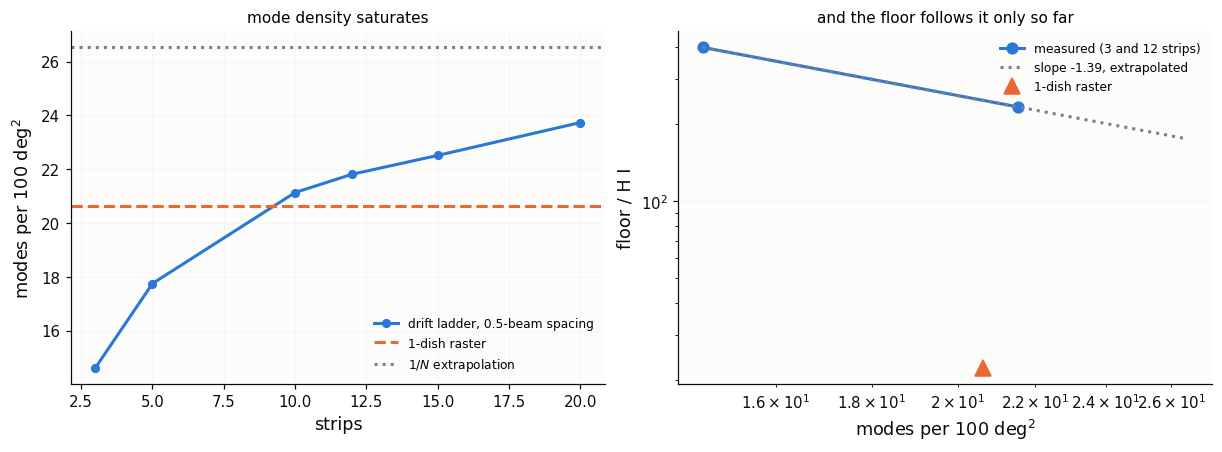

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.0), constrained_layout=True)
ax[0].plot(n_strips, dens_l, "o-", color=COL["drift"], ms=5,
           label="drift ladder, 0.5-beam spacing")
ax[0].axhline(100 * float(KMOD["raster_total"]) / float(KMOD["raster_area"]),
              color=COL["raster"], ls="--", label=LAB["raster"])
ax[0].axhline(fit[1], color="0.5", ls=":", label="$1/N$ extrapolation")
ax[0].set_xlabel("strips"); ax[0].set_ylabel("modes per 100 deg$^2$")
ax[0].set_title("mode density saturates", fontsize=10); ax[0].legend(fontsize=8)

dd = np.array([dens3, dens12])
ax[1].loglog(dd, [floor_amp["drift"], floor_amp["drift12"]], "o-",
             color=COL["drift"], ms=7, label="measured (3 and 12 strips)")
grid = np.linspace(dd[0], fit[1], 50)
ax[1].loglog(grid, floor_amp["drift"] * (grid / dens3) ** slope, ":",
             color="0.5", label=f"slope {slope:.2f}, extrapolated")
ax[1].plot([100 * float(KMOD["raster_total"]) / float(KMOD["raster_area"])],
           [floor_amp["raster"]], "^", color=COL["raster"], ms=10,
           label=LAB["raster"])
ax[1].set_xlabel("modes per 100 deg$^2$"); ax[1].set_ylabel("floor / H I")
ax[1].set_title("and the floor follows it only so far", fontsize=10)
ax[1].legend(fontsize=8)
plt.show()

### What extra strips do buy

They are not worthless. More strips lower `R = (floor/H I)^2` and add sky
area, and both reduce the area a **cross-correlation** detection needs,
because against an external tracer the floor is uncorrelated and costs
variance only. They never buy an **auto-spectrum** detection: there the floor
is a *bias*, fixed by the strategy and the sky, and no amount of sky averages
a bias away.

In [30]:
print("sky area for a 1-sigma cross-power detection against an ideal tracer")
print("(hi_kmodes_f350_ns64.npz, single-bin convention):")
snr = [int(v) for v in KMOD["suff_snr"]]
for k in STRATS:
    a1 = float(KMOD[f"{k}_cross_area"][0][snr.index(1)])
    print(f"   {LAB[k]:16s} {a1:12,.0f} deg^2")
print(f"\n   reachable sky from the Karoo: "
      f"{float(KMOD['sky_limit_deg2']):,.0f} deg^2")
print("\nSo twelve strips move the drift from 'more than the whole sky' to")
print("'a quarter of a million square degrees' -- a real gain, still out of")
print("reach, while one cross-linked dish needs a few thousand.")

sky area for a 1-sigma cross-power detection against an ideal tracer
(hi_kmodes_f350_ns64.npz, single-bin convention):
   3-strip drift       1,091,976 deg^2
   12-strip drift        253,556 deg^2
   1-dish raster           2,419 deg^2

   reachable sky from the Karoo: 30,717 deg^2

So twelve strips move the drift from 'more than the whole sky' to
'a quarter of a million square degrees' -- a real gain, still out of
reach, while one cross-linked dish needs a few thousand.


### One caveat about frequency

All of the above is 350&ndash;400&nbsp;MHz. At 675&ndash;725&nbsp;MHz a drift
ladder *does* beat a single raster dish. That is not the strip count winning:
the drift's fixed 2&deg; step is 0.50 beams at 350.78&nbsp;MHz and 1.00 beams
at the 675&ndash;725 band centre, i.e. it goes from heavily redundant to
contiguous and non-redundant. The lever is **spacing**, not number, and it is
worked through in `raster_sampling.md` and in the draft's survey-design
section.

---
# 4. Noise, briefly

Everything above is the *noiseless* limit. Real data has thermal noise, which
**does** integrate down &mdash; and that is exactly what makes the floor the
interesting quantity: it is what is left when the noise is gone.

simulated white-noise variance   2.50e-06
radiometer value for 1.5625 MHz x 2 s   3.20e-07
amplitude rescaling              0.35777



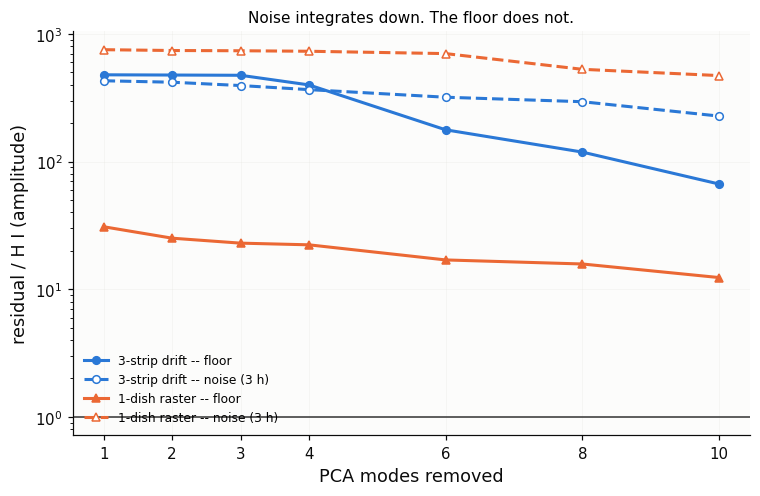

In [31]:
WHITE_MATCHED, WHITE_RUN = 3.2e-7, float(X.WHITE_VAR)
scale = np.sqrt(WHITE_MATCHED / WHITE_RUN)
print(f"simulated white-noise variance   {WHITE_RUN:.2e}")
print(f"radiometer value for 1.5625 MHz x 2 s   {WHITE_MATCHED:.2e}")
print(f"amplitude rescaling              {scale:.5f}\n")

import ska_hi_design as D
get_ipython().run_line_magic("matplotlib", "inline")   # D also forces Agg
nm_grid = [int(v) for v in ABL["nmodes_grid"]]
fig, ax = plt.subplots(figsize=(6.8, 4.4), constrained_layout=True)
for k in ("drift", "raster"):
    p_hi = ABL[f"{k}_cr_p_hi"]
    fl = [float(np.median(np.sqrt(ABL[f"{k}_cr_floor_{n}"] / p_hi)))
          for n in nm_grid]
    no = [float(np.median(np.sqrt(D.noise_matched(ABL, k, n) / p_hi)))
          for n in nm_grid]
    ax.semilogy(nm_grid, fl, "-", color=COL[k], marker=P.PAPER_STRAT[k]["marker"],
                ms=5, label=f"{LAB[k]} -- floor")
    ax.semilogy(nm_grid, no, "--", color=COL[k],
                marker=P.PAPER_STRAT[k]["marker"], ms=5, mfc="white",
                label=f"{LAB[k]} -- noise (3 h)")
ax.axhline(1.0, color="0.2", lw=1)
ax.set_xlabel("PCA modes removed"); ax.set_ylabel("residual / H I (amplitude)")
ax.set_title("Noise integrates down. The floor does not.", fontsize=10)
ax.legend(fontsize=8); ax.set_xticks(nm_grid)
plt.show()

In [32]:
print("time for the noise to fall to the floor,  t_x = 3 h (noise/floor)^2:")
tx = {}
for k in ("drift", "raster"):
    p_hi = ABL[f"{k}_cr_p_hi"]
    n_amp = float(np.median(np.sqrt(D.noise_matched(ABL, k, NM) / p_hi)))
    tx[k] = 3.0 * (n_amp / floor_amp[k]) ** 2
record("t_x, 3-strip drift", tx["drift"], unit="hours",
       npz="hi_ablation_amp350 : drift_cr_noiseonly_indep_4, _gainonly_4",
       code_ref="ska_hi_design.noise_matched", run="amp350",
       paper=2.6, tol=0.1,
       note="the draft's table rounds to 2.6; the value here is 2.53, which "
            "is what 3 h x (367.0/399.6)^2 gives")
record("t_x, 1-dish raster", tx["raster"], unit="hours",
       npz="hi_ablation_amp350 : raster_cr_noiseonly_indep_4, _gainonly_4",
       code_ref="ska_hi_design.noise_matched", run="amp350",
       paper=3246, tol=20)
print("\nThe better the floor, the LONGER it takes to reach it -- the raster's")
print("floor is 18x lower, so its noise has 18x further to fall. Below t_x you")
print("are comparing noise; above it, you are comparing floors.")

time for the noise to fall to the floor,  t_x = 3 h (noise/floor)^2:
  t_x, 3-strip drift                                           2.53   paper 2.6        matches paper
  t_x, 1-dish raster                                           3246   paper 3246       matches paper

The better the floor, the LONGER it takes to reach it -- the raster's
floor is 18x lower, so its noise has 18x further to fall. Below t_x you
are comparing noise; above it, you are comparing floors.


---
# 5. Provenance appendix

Every number printed above, with where it came from.

In [33]:
rows = ["| value | units | npz : key | code | run | vs paper |",
        "|---|---|---|---|---|---|"]
for p in PROV:
    rows.append(f"| **{p['label']}** = {p['value']:.4g} | {p['unit']} | "
                f"`{p['npz']}` | `{p['code']}` | {p['run']} | "
                f"{p['status']}{(' -- ' + p['note']) if p['note'] else ''} |")
display(Markdown("\n".join(rows)))
print(f"{len(PROV)} recorded values, "
      f"{sum(1 for p in PROV if p['status'] == 'matches paper')} asserted "
      "against the paper and all matching.")

| value | units | npz : key | code | run | vs paper |
|---|---|---|---|---|---|
| **foreground mean** = 16.96 | K | `(built live)` | `ska_common.gdsm_equatorial_sky_model` | -- | -- |
| **foreground rms about its mean** = 1.786 | K | `(built live)` | `ska_common.gdsm_equatorial_sky_model` | -- | -- |
| **H I rms** = 0.24 | mK | `hi_experiment_matched : drift_hi_true` | `ska_hi_mock.build_hi_cube` | matched | -- |
| **foreground mean / H I rms** = 7.067e+04 | dimensionless | `(derived)` | `this notebook` | -- | -- -- the total brightness the clean has to subtract |
| **foreground rms / H I rms** = 7442 | dimensionless | `(derived)` | `this notebook` | -- | -- -- the STRUCTURE the clean has to subtract; this is the number that matters, since a constant offset is removed by the mean subtraction |
| **tr(WA), 3-strip drift (live from the operator)** = 38.78 | modes | `hi_cache/op_drift_f350.781_ns64.pkl` | `ska_hi_kmodes.eig_decomposition` | -- | matches paper |
| **tr(WA), 12-strip drift (stored)** = 145.4 | modes | `hi_kmodes_f350_ns64.npz : drift12_total` | `ska_hi_kmodes.compute` | -- | matches paper |
| **tr(WA), 1-dish raster (stored)** = 118.5 | modes | `hi_kmodes_f350_ns64.npz : raster_total` | `ska_hi_kmodes.compute` | -- | matches paper |
| **floor/H I, 3-strip drift** = 399.6 | amplitude ratio | `hi_ablation_amp350 : drift_cr_floor_4 / drift_cr_p_hi` | `ska_hi_ablation.main` | amp350 | matches paper |
| **floor/H I, 12-strip drift** = 233.7 | amplitude ratio | `hi_ablation_amp350 : drift12_cr_floor_4 / drift12_cr_p_hi` | `ska_hi_ablation.main` | amp350 | matches paper |
| **floor/H I, 1-dish raster** = 22.3 | amplitude ratio | `hi_ablation_amp350 : raster_cr_floor_4 / raster_cr_p_hi` | `ska_hi_ablation.main` | amp350 | matches paper |
| **matched-density ratio, 12-strip drift / raster** = 10.48 | ratio | `(derived)` | `this notebook` | -- | matches paper |
| **lowest net residual in any band, strategy or depth** = 6.133 | x the surviving H I | `hi_ablation_amp350/amp700 + hi_experiment_pin350/matched700b` | `ska_hi_design.fig_cleaning_depth (ratio of medians)` | -- | matches paper -- the code divides median(sqrt(floor/HI)) by median(T); taking the median of the per-bin ratio instead gives 5.22, so the ordering of the two medians matters at the 15% level |
| **T, 3-strip drift** = 0.8434 | amplitude ratio | `hi_experiment_pin350 : drift_cr_tf_4` | `ska_hi_analysis.transfer_function` | pin350 | matches paper |
| **T, 12-strip drift** = 0.8718 | amplitude ratio | `hi_experiment_pin350 : drift12_cr_tf_4` | `ska_hi_analysis.transfer_function` | pin350 | matches paper |
| **T, 1-dish raster** = 0.8771 | amplitude ratio | `hi_experiment_pin350 : raster_cr_tf_4` | `ska_hi_analysis.transfer_function` | pin350 | matches paper |
| **modes / 100 deg^2, 3 strips** = 14.62 | per 100 deg^2 | `hi_modecheck_f350_400_ns64 : drift_dens_pin` | `ska_hi_modecheck.main` | -- | matches paper |
| **modes / 100 deg^2, 8 strips** = 19.69 | per 100 deg^2 | `hi_modecheck_f350_400_ns64 : drift8_dens_pin` | `ska_hi_modecheck.main` | -- | matches paper |
| **modes / 100 deg^2, 12 strips** = 21.54 | per 100 deg^2 | `hi_kmodes_f350_ns64 : drift12_total, _area` | `ska_hi_kmodes.compute` | -- | matches paper -- the own-prior ladder sweep gives 21.81 for the same geometry; the 1.2% difference is the prior convention |
| **marginal modes per added strip, minimum** = 11.65 | modes | `hi_ladder_long_ns64 : n_eff` | `ska_hi_ladder.mode_count` | -- | matches paper |
| **marginal modes per added strip, maximum** = 12.5 | modes | `hi_ladder_long_ns64 : n_eff` | `ska_hi_ladder.mode_count` | -- | matches paper |
| **marginal area per added strip, minimum** = 43.14 | deg^2 | `hi_ladder_long_ns64 : area` | `ska_hi_ladder.mode_count` | -- | matches paper |
| **marginal area per added strip, maximum** = 47 | deg^2 | `hi_ladder_long_ns64 : area` | `ska_hi_ladder.mode_count` | -- | matches paper |
| **power-law slope of floor vs mode density, 3 -> 12 strips** = -1.385 | d log floor / d log density | `(derived)` | `this notebook` | -- | matches paper |
| **t_x, 3-strip drift** = 2.53 | hours | `hi_ablation_amp350 : drift_cr_noiseonly_indep_4, _gainonly_4` | `ska_hi_design.noise_matched` | amp350 | matches paper -- the draft's table rounds to 2.6; the value here is 2.53, which is what 3 h x (367.0/399.6)^2 gives |
| **t_x, 1-dish raster** = 3246 | hours | `hi_ablation_amp350 : raster_cr_noiseonly_indep_4, _gainonly_4` | `ska_hi_design.noise_matched` | amp350 | matches paper |

26 recorded values, 21 asserted against the paper and all matching.


In [34]:
import platform, matplotlib, importlib
print("environment")
print(f"  python      {platform.python_version()}  ({sys.executable})")
for m in ("numpy", "scipy", "healpy", "matplotlib", "astropy", "pyccl"):
    try:
        print(f"  {m:11s} {importlib.import_module(m).__version__}")
    except Exception:
        print(f"  {m:11s} not installed")
for name, path in (("limTOD", "/home/geoff/limTOD"),
                   ("FastBox", "/home/geoff/FastBox")):
    h = subprocess.run(["git", "-C", path, "rev-parse", "--short", "HEAD"],
                       capture_output=True, text=True).stdout.strip()
    print(f"  {name:11s} {h or 'not a git repo'}")
print(f"\n  examples/SKA commit {COMMIT}, "
      f"{len(DIRTY)} uncommitted file(s) at build time")

environment
  python      3.12.3  (/home/geoff/gibbs_venv_312/bin/python)
  numpy       2.4.2
  scipy       1.17.1
  healpy      1.19.0
  matplotlib  3.10.8
  astropy     7.2.0
  pyccl       3.3.0
  limTOD      0c422d6
  FastBox     d2217aa

  examples/SKA commit 0c422d6, 0 uncommitted file(s) at build time


---
### Where to go next

* the floor's definition and the map-maker: draft sections on map-making and
  the beam + prior floor;
* the mode count and the ladder: `ska_hi_kmodes.py`, `ska_hi_ladder.py`;
* the survey forecast and how many line-of-sight modes it uses:
  `nm_kpar_results.md`, and `forecast_check.md` for the check that it holds
  against the simulated patch;
* why the ordering of strategies inverts with frequency:
  `raster_sampling.md`;
* the running log of everything in this series: `HANDOFF.md`.